# Main Test Profile: Noise Sensitivity Test


In [1]:
from pathlib import Path
from collections import defaultdict
from functools import partial
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from tqdm.auto import tqdm
from IPython.display import display
from diffusers import UNet2DConditionModel, MultiControlNetModel
from diffusers.utils.torch_utils import randn_tensor

from myddim_schedule import DDIMScheduler
from utils import wavelet_forward, calc_metrics
from inference_utils import get_impedance_cmap
from paper_plotting import section_figure_size, paper_section, paper_colorbar as add_colorbar
from inversion_utils import (
    make_background_filter, initial_fn, forward_wavelet_fn,
)


## 1. Device, Model, and Schedulers


In [2]:
ROOT = Path.cwd().resolve()
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
path = ROOT / "weights" / "checkpoint-22608"

torch.set_num_threads(8)
if device.type == "cuda":
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cuda.matmul.allow_tf32 = False

unet = UNet2DConditionModel.from_pretrained(path, subfolder="unet").to(device)
controlnet = MultiControlNetModel.from_pretrained(str(path / "controlnet/controlnet")).to(device)
unet.eval().requires_grad_(False)
controlnet.eval().requires_grad_(False)
scheduler = DDIMScheduler.from_pretrained(path, subfolder="scheduler")
scheduler2 = DDIMScheduler.from_pretrained(path, subfolder="scheduler")
if scheduler.config.prediction_type != "v_prediction" or scheduler.config.num_train_timesteps != 1500:
    raise ValueError("The checkpoint prediction type or number of training timesteps does not match the settings used in the paper.")
print("Device:", device)

# Keep the original test-script switch; denoising always runs under no_grad.
unet.enable_gradient_checkpointing()
controlnet.enable_gradient_checkpointing()


The config attributes {'add_attention': True, 'attn_norm_num_groups': None, 'downsample_type': 'conv', 'num_train_timesteps': None, 'upsample_type': 'conv'} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Device: cuda:3


## 2. Select a Profile and Observation Setting


In [3]:
data_dir = ROOT / "data" / "sensitivity" / "section_main_vol00983_slice_363"
output_dir = ROOT / "results" / "sensitivity_noise" / data_dir.name
output_dir.mkdir(parents=True, exist_ok=True)
metadata = json.loads((data_dir / "section_metadata.json").read_text(encoding="utf-8"))
scan_values = [30, 20, 10, 5]
fixed_frequency_hz = 25
settings = [
    setting for value in scan_values for setting in metadata["settings"]
    if setting["snr_db"] == value and setting["frequency_hz"] == fixed_frequency_hz]
if len(settings) != len(scan_values):
    raise ValueError("The selected observation settings are missing or duplicated in the current data directory.")
with np.load(data_dir / settings[0]["file"], allow_pickle=False) as stored:
    preview = {name: stored[name] for name in stored.files}
print("Input:", data_dir)
print("Output:", output_dir)
display(pd.DataFrame([{"file": s["file"], "frequency_hz": s["frequency_hz"],
                       "snr_db": s["snr_db"]} for s in settings]))


Input: /wzg3/home/hanlong/MyProject/2DGeoDiffInv/data/sensitivity/section_main_vol00983_slice_363
Output: /wzg3/home/hanlong/MyProject/2DGeoDiffInv/results/sensitivity_noise/section_main_vol00983_slice_363


,file,frequency_hz,snr_db
0,f025_snr30_w02.npz,25,30
1,f025_snr20_w02.npz,25,20
2,f025_snr10_w02.npz,25,10
3,f025_snr05_w02.npz,25,5


## 3. Impedance Section and Observed Seismic Data


In [4]:
imp_min = float(settings[0]["scalars"]["imp_min"])
imp_max = float(settings[0]["scalars"]["imp_max"])
raw_image_denorm = torch.from_numpy(preview["target"]).float().to(device)
raw_image = (raw_image_denorm - imp_min) / (imp_max - imp_min)
seis_slice = torch.from_numpy(preview["observed"]).float().to(device)
seis_min, seis_max = seis_slice.min(), seis_slice.max()
seis_amplitude = torch.maximum(seis_min.abs(), seis_max.abs())

# Preserve the original 0.5 offset and restoration order to keep floating-point normalization unchanged.
seis = (seis_slice / seis_amplitude * 0.5 + 0.5).cpu().squeeze(0)
f0 = float(settings[0]["frequency_hz"])
dt = float(metadata["dt_s"])
cmap = get_impedance_cmap("testset")
cmap2 = plt.get_cmap("seismic")
plot_min, plot_max = imp_min * 1.4, imp_max * 0.9
aspect = 1
print("Shape:", tuple(raw_image.shape[-2:]), "| dt:", dt)

# The following settings only format the article figures; they do not affect normalization, forward modeling, or metrics.
plot_options = dict(dataset="testset", wells=metadata.get("well_starts", ()),
                    well_width=int(metadata.get("well_width", 3)), dt=dt)


Shape: (512, 512) | dt: 0.001


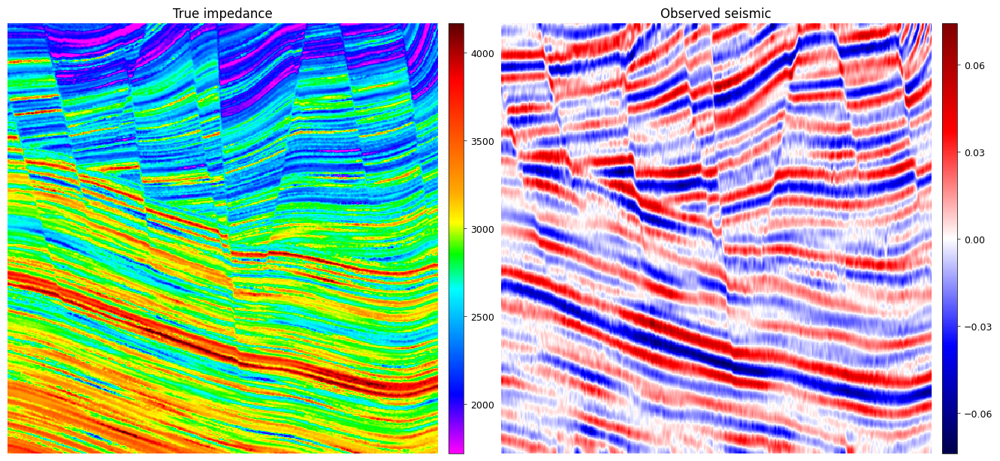

In [5]:
plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(raw_image_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("True impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(seis_slice[0, 0].cpu().T, cmap=cmap2, vmin=-seis_amplitude,
           vmax=seis_amplitude, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=False,
              show_wells=False, **plot_options)
plt.title("Observed seismic")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 4. Well Logs and Masks


Well starts: [30, 400]


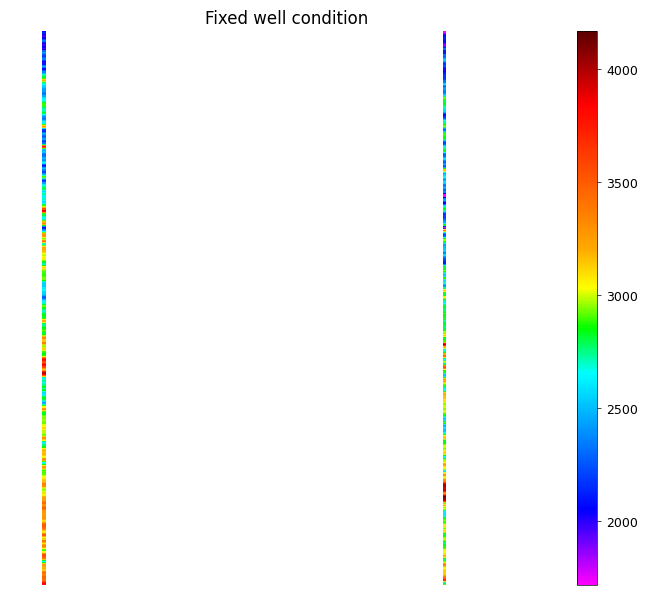

In [6]:
data_well_slice = torch.from_numpy(preview["well_image"][0]).float().to(device)
mask_well_slice = torch.from_numpy(preview["well_mask"][0]).float().to(device)
if data_well_slice.shape != raw_image.shape or mask_well_slice.shape != raw_image.shape:
    raise ValueError("Well logs, masks, and impedance must have matching dimensions.")
if mask_well_slice.sum() <= 0:
    raise ValueError("Wavelet estimation requires at least one valid well-log segment.")
if (data_well_slice * (1 - mask_well_slice)).any():
    raise ValueError("Well-log conditions must be zero outside the mask.")
well_images = data_well_slice.unsqueeze(0)
mask = mask_well_slice.unsqueeze(0)

columns = torch.where(mask[0, 0].any(dim=-1))[0].cpu().numpy()
dot = columns[np.r_[True, np.diff(columns) > 1]].tolist()
print("Well starts:", dot)
well_images_denorm = (well_images * 0.5 + 0.5) * (imp_max - imp_min) + imp_min
# Well overlays come from the actual input logs and masks and are used only for display.
plot_options.update(wells=dot,
                    well_values=well_images_denorm[0, 0].detach().cpu().numpy(),
                    well_mask=mask[0, 0].detach().cpu().numpy())
shown_wells = np.ma.masked_where(mask[0, 0].cpu().numpy().T == 0,
                                well_images_denorm[0, 0].cpu().numpy().T)
plt.figure(figsize=section_figure_size(raw_image.shape[-2:], cols=1, dataset=plot_options["dataset"]))
plt.imshow(shown_wells, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("Fixed well condition")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 5. Initial Low-Frequency Model


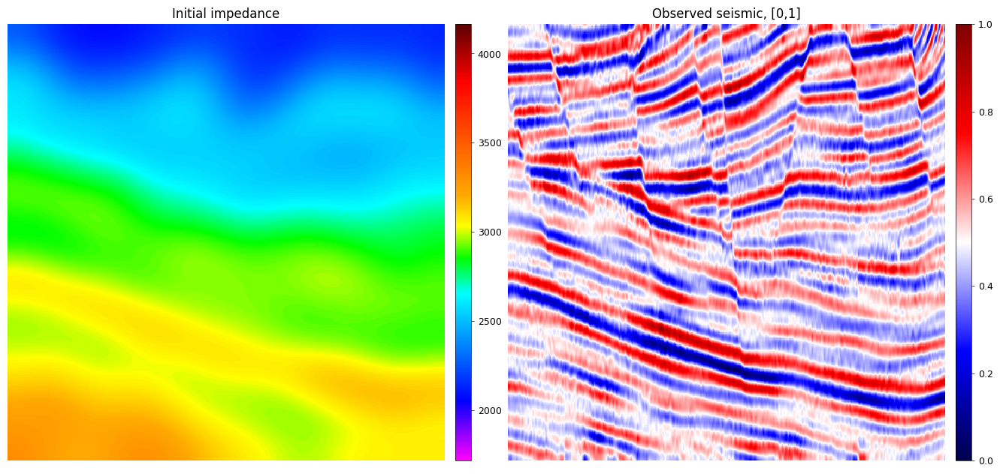

In [7]:
ks = 201
# The fixed initial model is already normalized to [0,1]; use it directly without additional smoothing.
smoothed = torch.from_numpy(preview["initial_model"]).float().to(device)
if smoothed.shape != raw_image.shape:
    raise ValueError("The initial model and true impedance have different dimensions.")
smoothed_denorm = smoothed * (imp_max - imp_min) + imp_min

plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(smoothed_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("Initial impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(seis[0].cpu().T, cmap=cmap2, vmin=0, vmax=1, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=False,
              show_wells=False, **plot_options)
plt.title("Observed seismic, [0,1]")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 6. Normalization, Background Operator, and Evaluation Range


In [8]:
image_shape = (1, 1, *raw_image.shape[-2:])
smoothed_norm = (smoothed.unsqueeze(0) - 0.5) / 0.5
cond_image = (seis.unsqueeze(0).to(device) - 0.5) / 0.5
scaled_seismic = cond_image * torch.maximum(seis_min.abs(), seis_max.abs())
scaled_seismic = torch.sign(scaled_seismic) * torch.pow(scaled_seismic.abs(), 1)
cond_image_denoise = scaled_seismic / torch.maximum(
    scaled_seismic.min().abs(), scaled_seismic.max().abs())
well_image2 = well_images.to(device)
# The original sensitivity script builds the Gaussian kernel in NumPy and then converts it to float32.
# Choose "conv2d" or "fft"; retain the original convolution by default without changing the kernel or inversion parameters.
background_implementation = "conv2d"
background_filter = make_background_filter(
    smoothed_norm, ks, torch_kernel=False,
    implementation=background_implementation)
print("Image shape:", image_shape, "| Normalized seismic:", tuple(cond_image.shape))


Image shape: (1, 1, 512, 512) | Normalized seismic: (1, 1, 512, 512)


## 7. Fixed Observations and Known Wavelets


In [9]:
window_new = (raw_image.shape[-2], raw_image.shape[-1] // 32)
wavelet_mat = torch.from_numpy(preview["wavelet"]).float().to(device)
print("Known wavelet shape:", tuple(wavelet_mat.shape), "| Forward window:", window_new)


Known wavelet shape: (1, 32, 501) | Forward window: (512, 16)


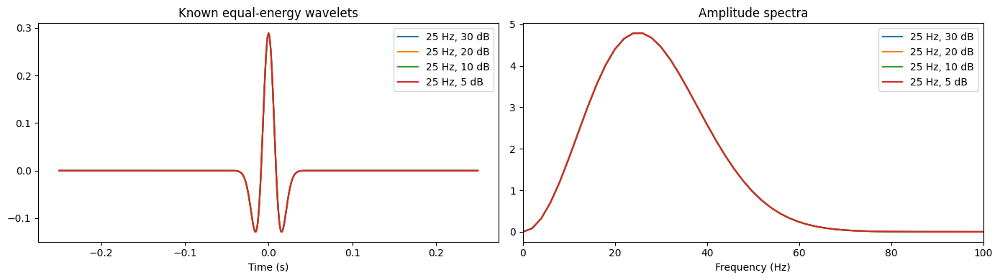

In [10]:
plt.figure(figsize=(14, 4))
for setting in settings:
    with np.load(data_dir / setting["file"], allow_pickle=False) as stored:
        wavelet = stored["wavelet"][0, 0].copy()
    label = f'{setting["frequency_hz"]} Hz, {setting["snr_db"]} dB'
    time_axis = (np.arange(len(wavelet)) - len(wavelet) // 2) * dt
    plt.subplot(121)
    plt.plot(time_axis, wavelet, label=label)
    plt.subplot(122)
    plt.plot(np.fft.rfftfreq(len(wavelet), dt), np.abs(np.fft.rfft(wavelet)), label=label)
plt.subplot(121)
plt.title("Known equal-energy wavelets")
plt.xlabel("Time (s)")
plt.legend()
plt.subplot(122)
plt.title("Amplitude spectra")
plt.xlabel("Frequency (Hz)")
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


## 8. Forward Modeling at Well Locations


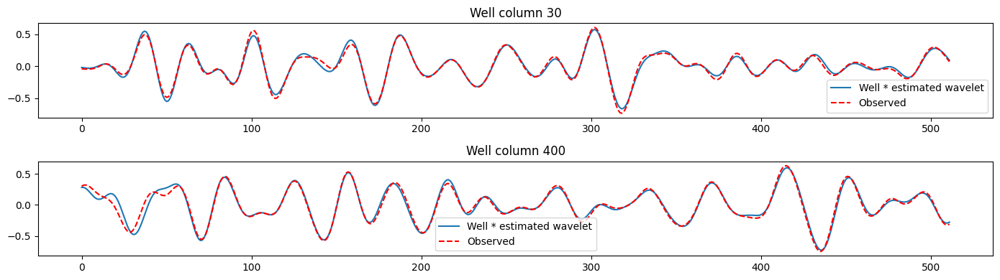

In [11]:
with torch.no_grad():
    seis_forward2 = wavelet_forward(
        wavelet_mat, data_well_slice.unsqueeze(0), window_new,
        seis_min, seis_max, imp_min, imp_max)
plt.figure(figsize=(14, max(3, 2 * len(dot))))
for j, trace in enumerate(dot):
    plt.subplot(len(dot), 1, j + 1)
    plt.plot(seis_forward2[0, 0, trace].cpu(), label="Well * estimated wavelet")
    plt.plot(cond_image[0, 0, trace].cpu(), "r--", label="Observed")
    plt.title(f"Well column {trace}")
    plt.legend()
plt.tight_layout()
plt.show()


## 9. Denoising and Data Fitting


In [12]:
def batch_tv(data):
    dims = data.shape
    score = 0
    if len(dims) == 3:
        for i in range(data.shape[0]):
            vol = data[i]       
            diff1 = vol[1:] - vol[:-1]
            diff2 = vol[:, 1:] - vol[:, :-1]
            res1 = diff1.abs().sum()
            res2 = diff2.abs().sum()
            # res1 = torch.linalg.norm(diff1, ord=1)
            # res2 = torch.linalg.norm(diff2, ord=1)
            score += res1 + 1 * res2 

    else:
        raise ValueError("Unsupported data dimensionality. Expected 3 or 4 dimensions, got {}.".format(data.dim()))
    return score

def denoise(begin_step, image, num_steps, scheduler, cond_image, well_image,
            eta=1, scale=(1, 1), generator=None):
    # Keep the original interface; each round requests num_steps=N_rev with both conditioning networks.
    with torch.no_grad():
        steps = max(int(begin_step), 0)
        timesteps = (np.linspace(steps, 0, min(num_steps, round(steps))).round().astype(np.int64)
                     if steps != 0 else np.array([0]))
        scheduler.set_timesteps(timesteps=timesteps)
        for t in scheduler.timesteps:
            one = torch.ones((image.shape[0], 1, 1, 1), device=image.device, dtype=image.dtype)
            down_samples, mid_sample = controlnet(
                image, t, encoder_hidden_states=None,
                controlnet_cond=[cond_image, well_image],
                conditioning_scale=[one * scale[0], one * scale[1]],
                guess_mode=False, return_dict=False)
            model_output = unet(
                image, t, None,
                down_block_additional_residuals=down_samples,
                mid_block_additional_residual=mid_sample).sample
            image, image_pred_ori = scheduler.step(
                model_output, t, image, use_clipped_model_output=True,
                generator=generator, eta=eta, return_dict=False)
    return image, image_pred_ori, timesteps


In [13]:
def data_fitting(image_dif, image_denoise, net, opti_old, num_iterations, lr,
                 forward_fns, scale, wavelet_mat):
    image_init = image_denoise.clone().detach()
    net.train()

    # Keep parameters across rounds, recreate the optimizer each round, and do not carry Adam moments between rounds.
    for param_group in opti_old.param_groups:
        param_group["lr"] = float(lr)
    opti = type(opti_old)(opti_old.param_groups, **opti_old.defaults)

    norm_dics = defaultdict(list)
    for _ in range(num_iterations):
        image = image_init + net(image_dif).reshape_as(image_init)
        opti.zero_grad()
        values = {
            "forward_wavelet": forward_fns["forward_wavelet"](image=image, wavelet_mat=wavelet_mat),
            "tv": batch_tv(image[:, 0]),
            "initial": forward_fns["initial"](image=image),
            "data_keep": torch.linalg.norm(image - image_init) ** 2,
        }
        norm = sum(scale[key] * value for key, value in values.items())
        norm.backward()
        opti.step()
        for key, value in values.items():
            norm_dics[key].append(float(value.detach()))

    with torch.no_grad():
        net.eval()
        image_fit = (image_init + net(image_dif).reshape_as(image_init)).clamp(-1, 1)
    return image_fit.detach(), norm_dics


## 10. Inversion Parameters


In [14]:
seed = 42
epochs = 90
N_rev = 5
num_iterations = 10
eta = 1
noise_floor = 1
plot_interval = max(1, epochs // 5)
forward_wavelet_weight = 0.2
tv_weight = 0.0
initial_weight = 1.0
datakeep_weight = 2.0
lr_scheduler = np.linspace(0.0001, 0.001, epochs)
scale_scheduler_well = np.linspace(4.0, 0.2, epochs)
timesteps = np.linspace(1320, 0, epochs).round().astype(np.int64)
noise_schedule_steps = 50
if min(epochs, N_rev, num_iterations) < 1:
    raise ValueError("epochs, N_rev, and num_iterations must be positive.")
print("Outer iterations:", epochs, "| N_rev:", N_rev, "| Fitting steps:", num_iterations)

# Set background_implementation in the earlier condition-preparation cell; rerun that cell after changing it.


Outer iterations: 90 | N_rev: 5 | Fitting steps: 10


## 11. Inversion for Each Observation Setting


Condition: 25 Hz, 30 dB


25 Hz, 30 dB:   0%|          | 0/90 [00:00<?, ?it/s]

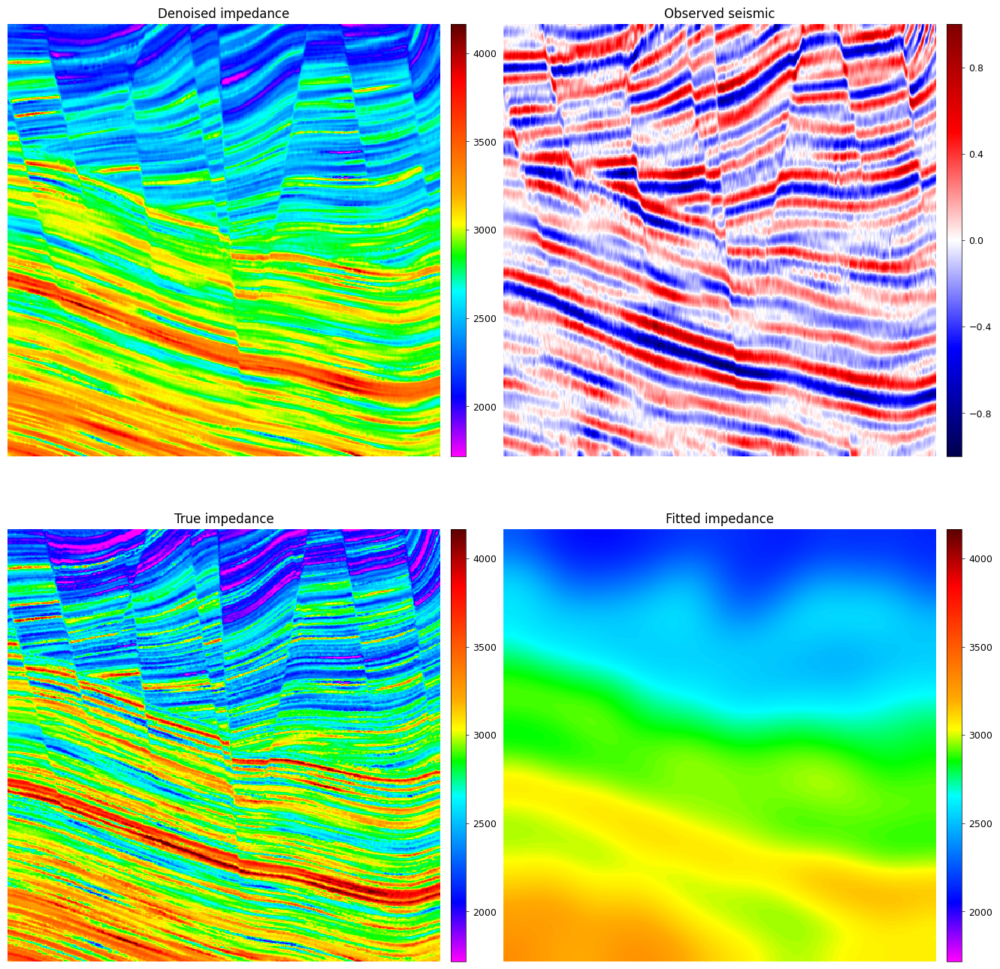

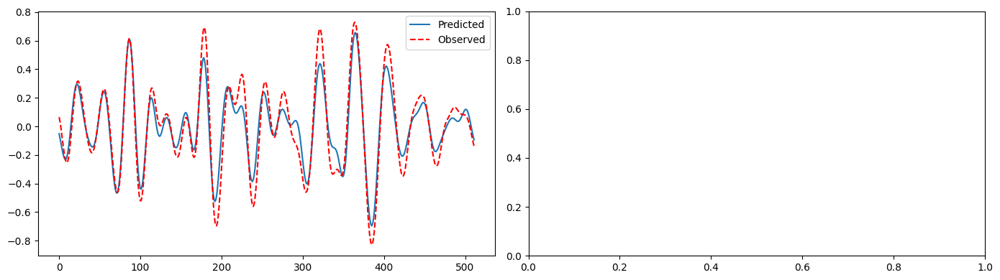

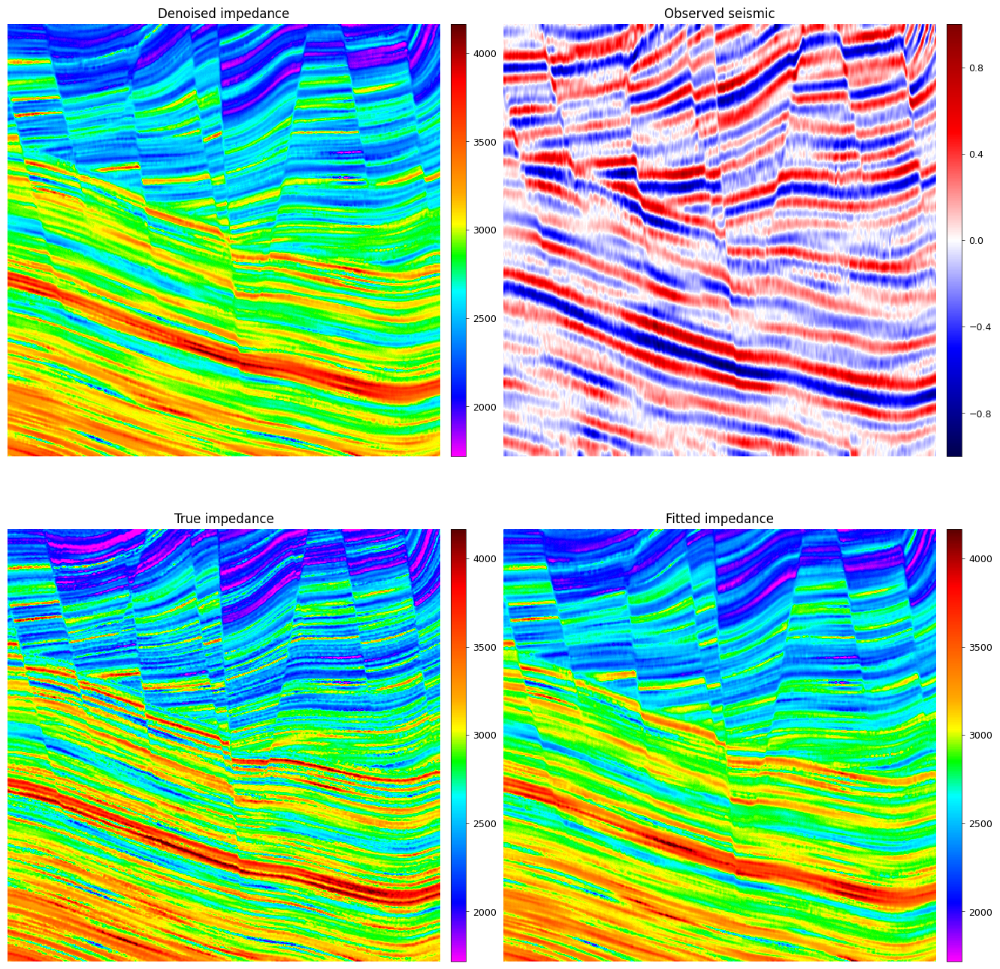

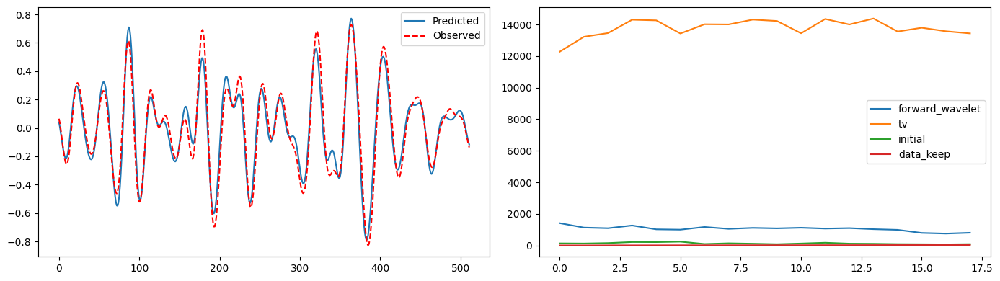

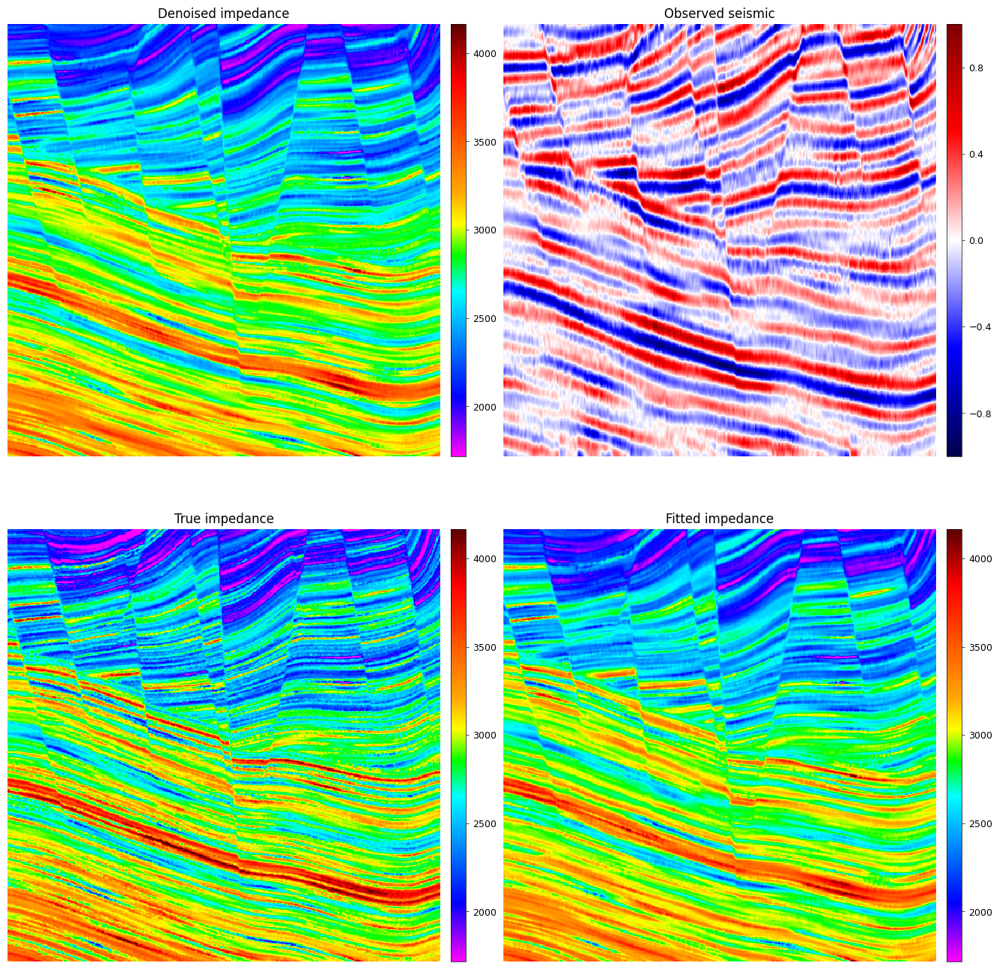

...

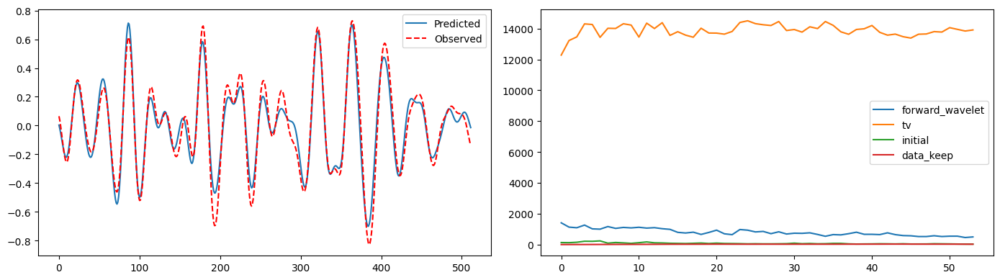

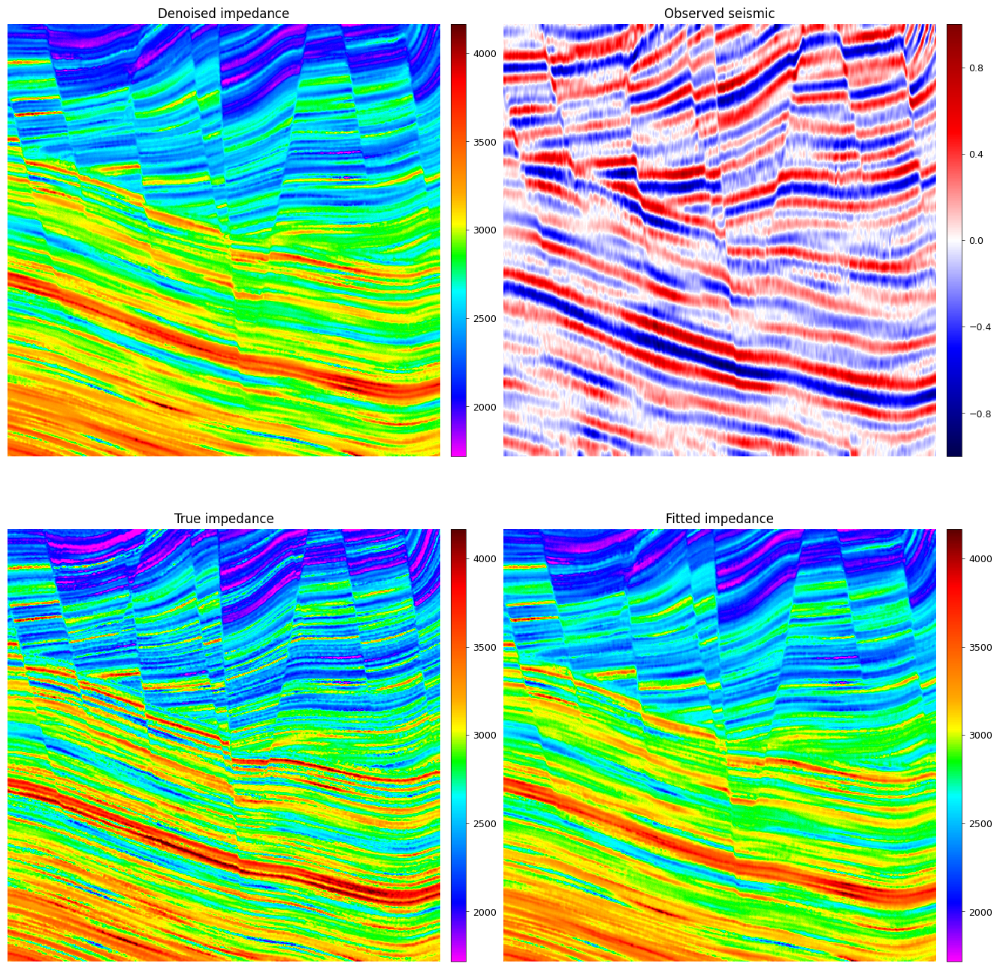

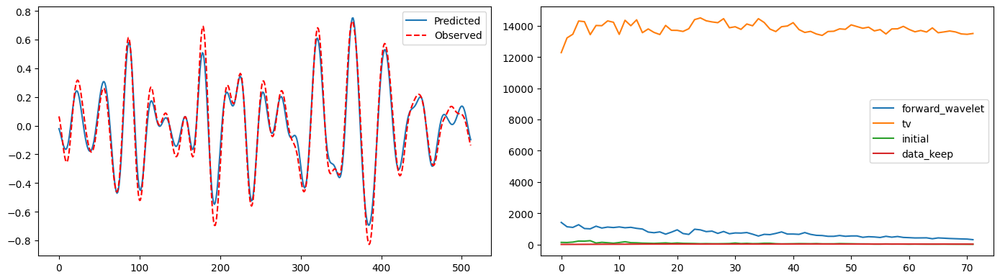

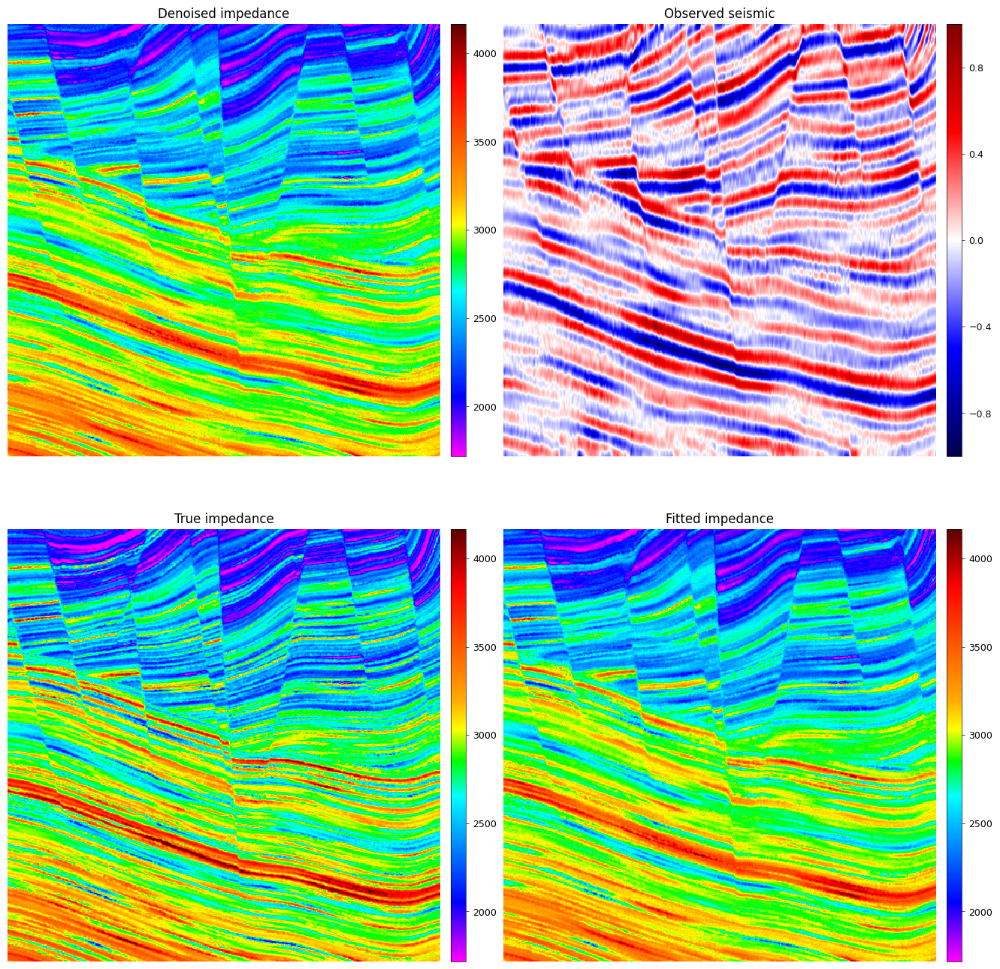

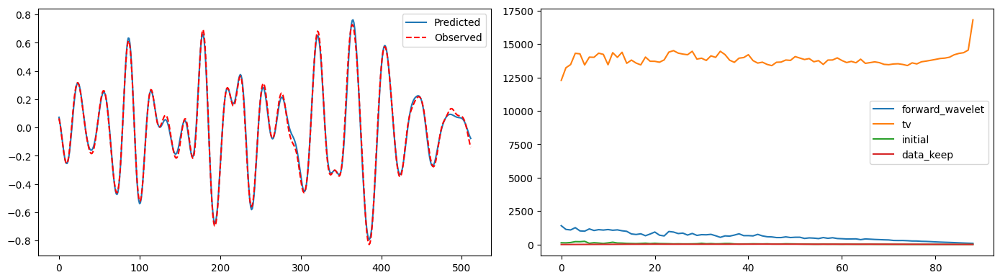

Metrics: {'RMSE': 179.1595916748047, 'PSNR': 25.569884906191106, 'SSIM': 0.5646157264709473, 'MAE': 132.68148803710938, 'CorrCoef': 0.9074270919176984, 'WellRMSE': 52.221710205078125, 'FixedAwayFromWellsRMSE': 179.4385986328125, 'ObservedSeismicRMSE_normalized': 0.018733086064457893, 'CleanSeismicRMSE': 0.0013955768663436174} | UNet calls: 446 | Fitting updates: 890
Condition: 25 Hz, 20 dB


25 Hz, 20 dB:   0%|          | 0/90 [00:00<?, ?it/s]

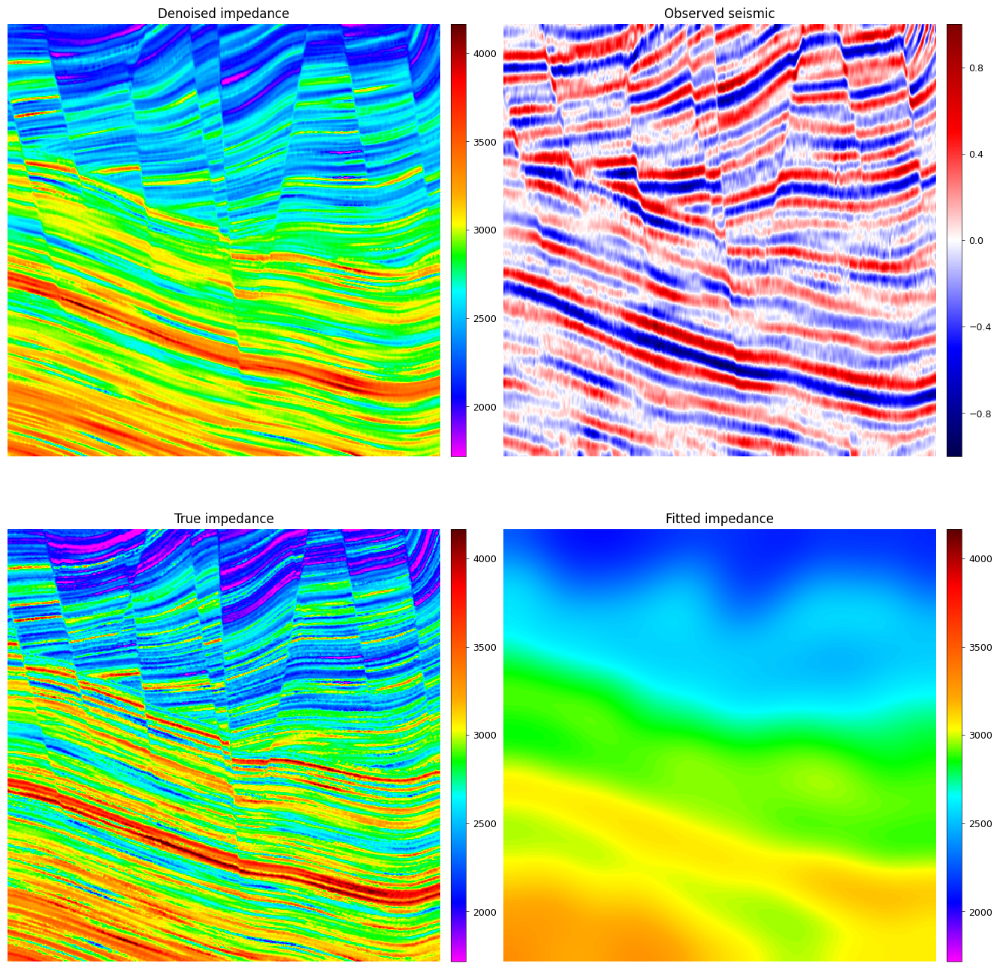

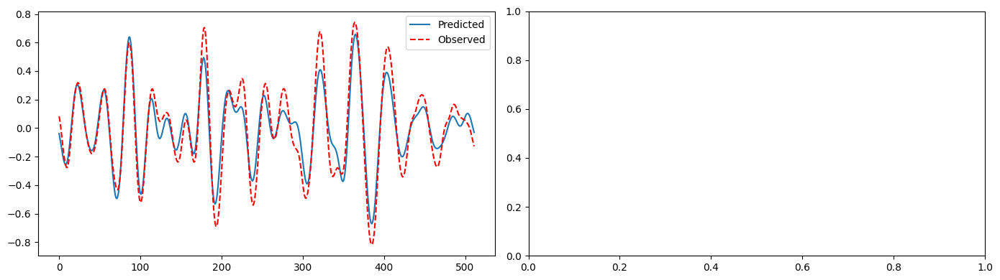

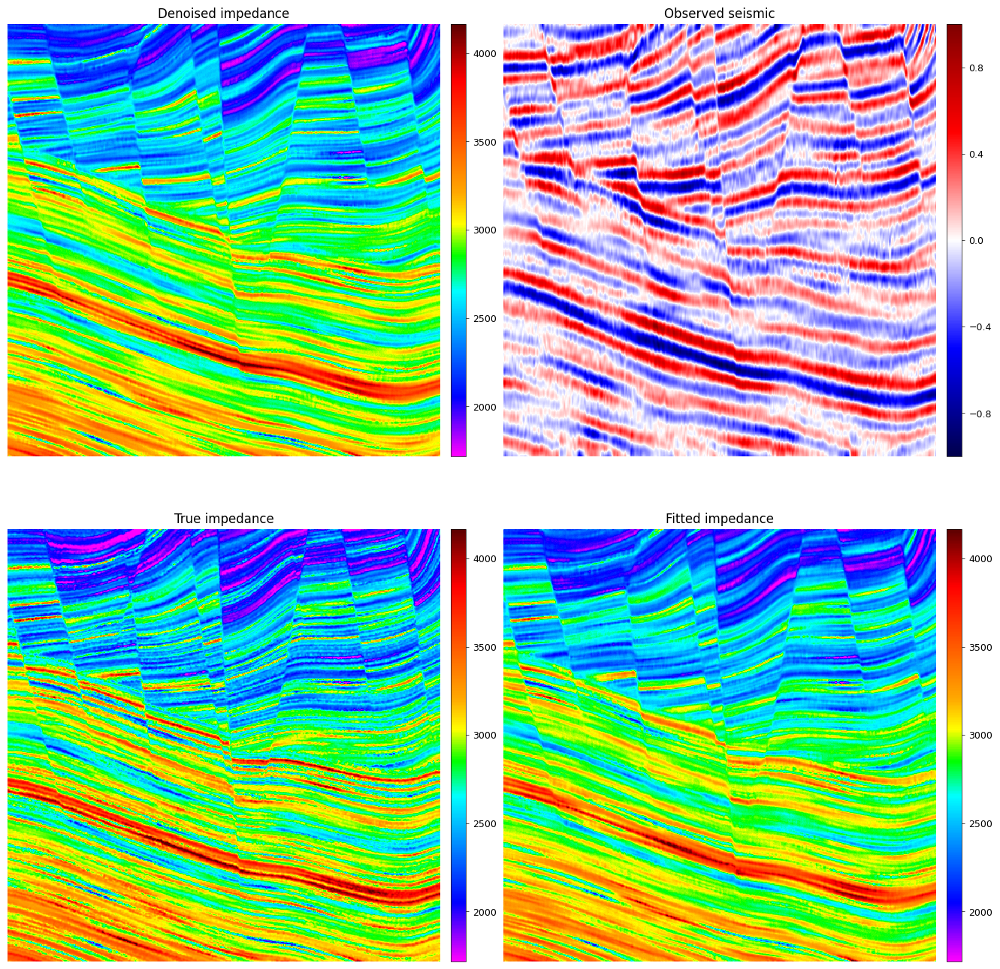

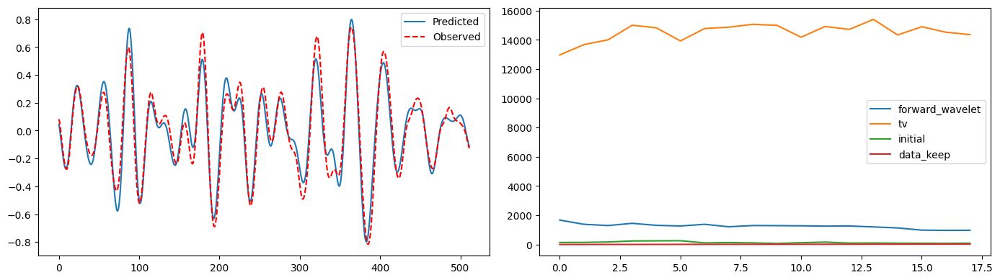

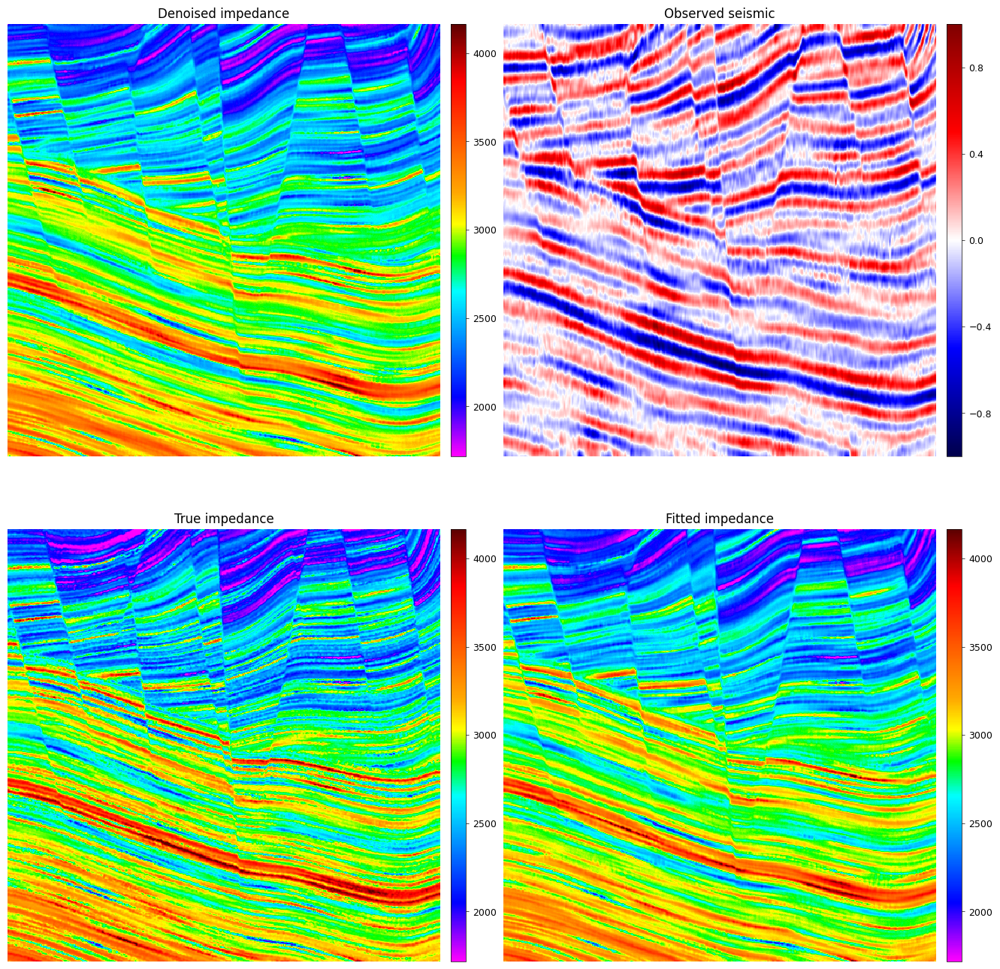

...

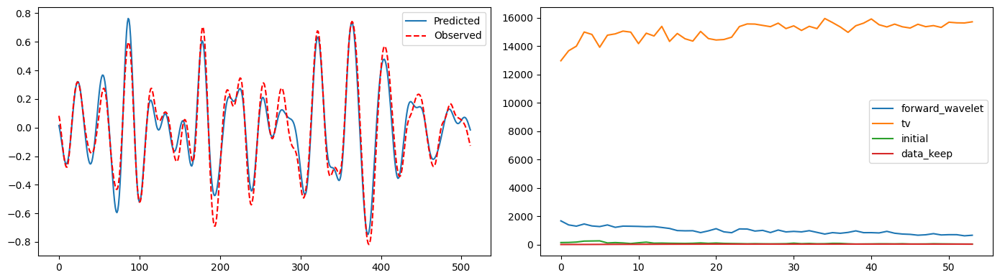

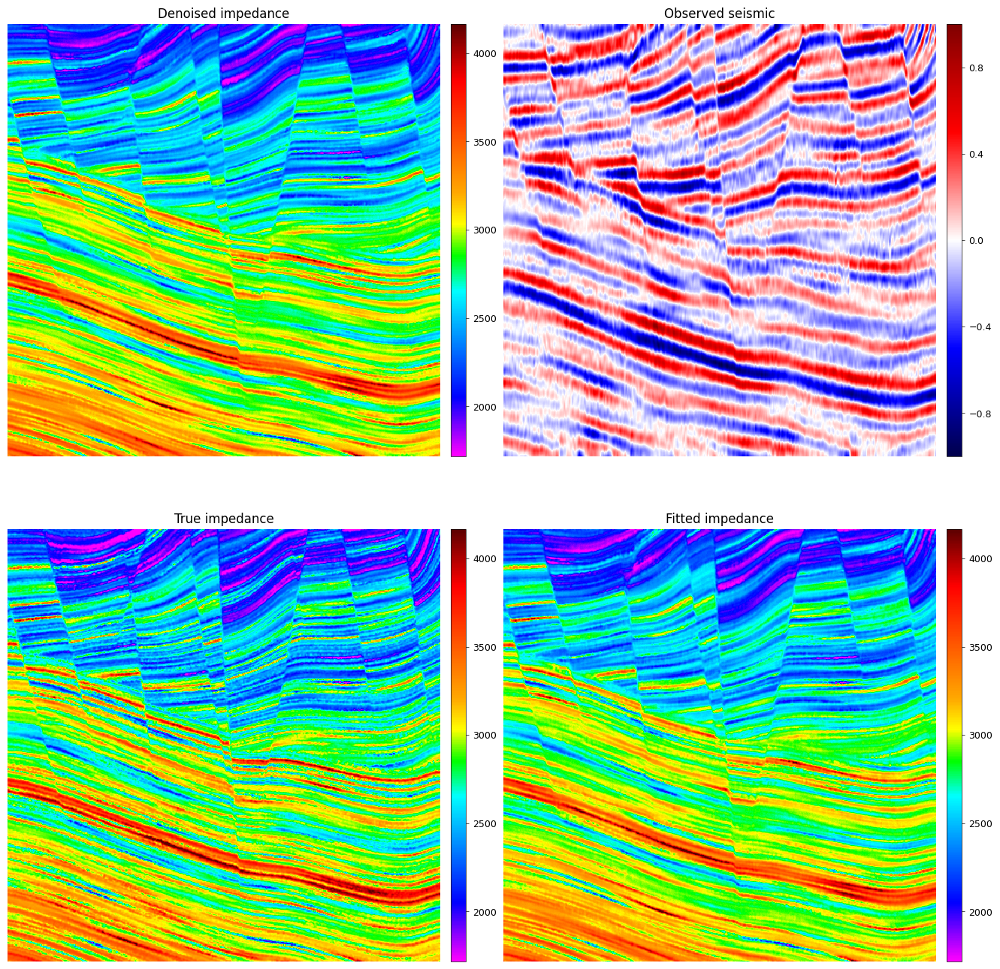

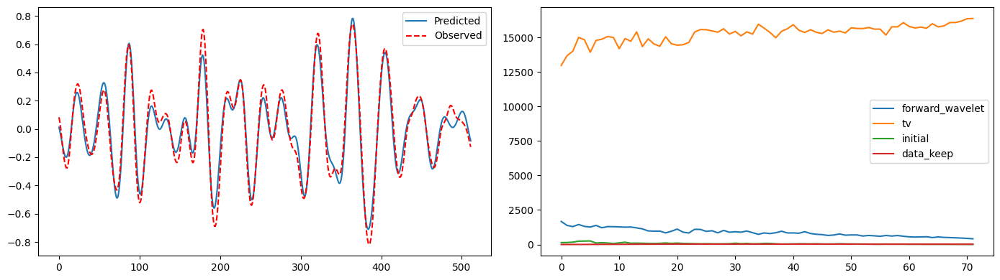

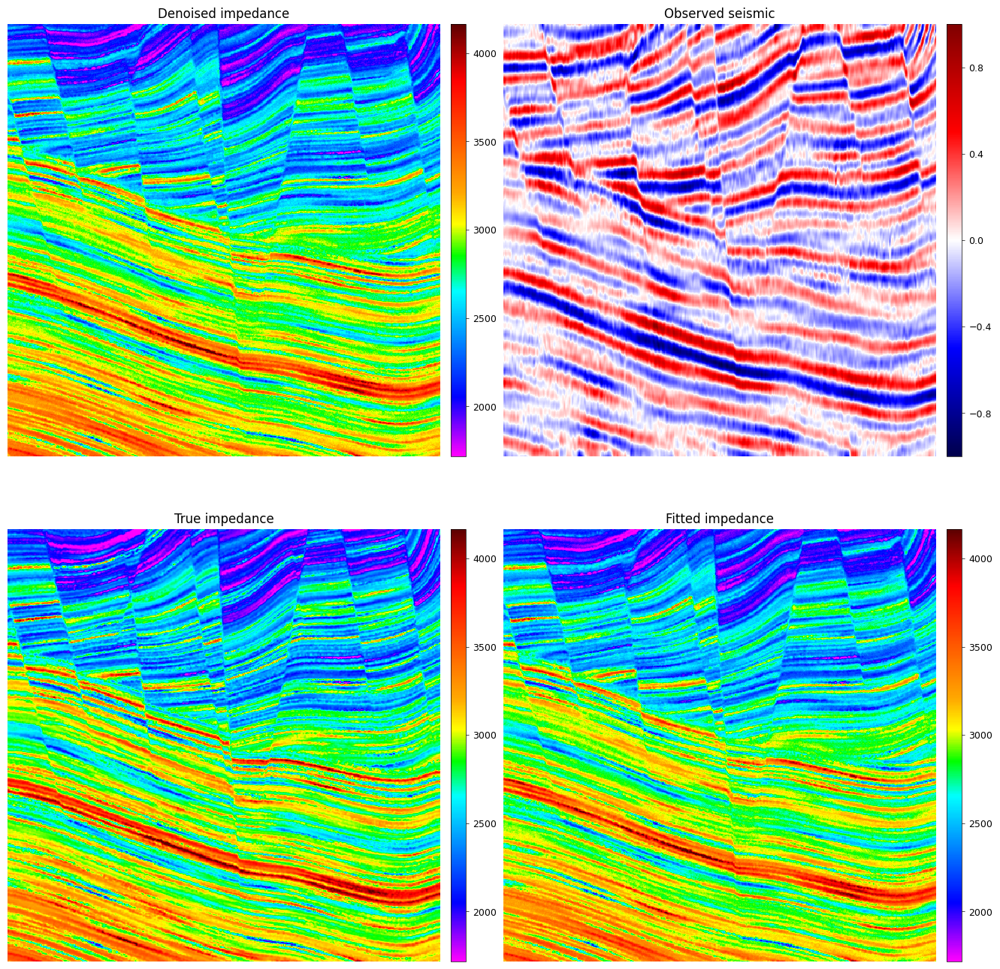

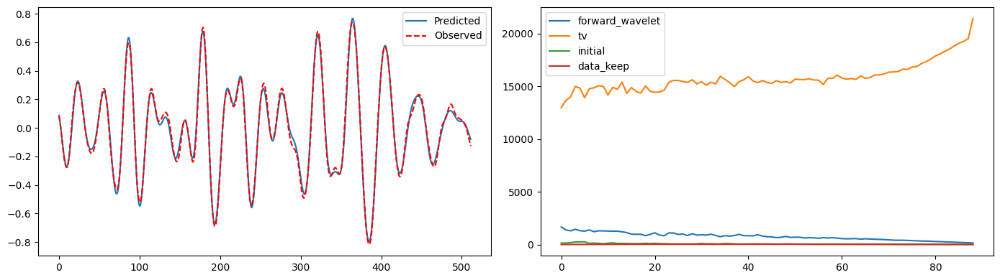

Metrics: {'RMSE': 196.8614044189453, 'PSNR': 24.751474604352094, 'SSIM': 0.5248820185661316, 'MAE': 145.69662475585938, 'CorrCoef': 0.8892447798502907, 'WellRMSE': 52.15192794799805, 'FixedAwayFromWellsRMSE': 197.19923400878906, 'ObservedSeismicRMSE_normalized': 0.024513447657227516, 'CleanSeismicRMSE': 0.0018480295548215508} | UNet calls: 446 | Fitting updates: 890
Condition: 25 Hz, 10 dB


25 Hz, 10 dB:   0%|          | 0/90 [00:00<?, ?it/s]

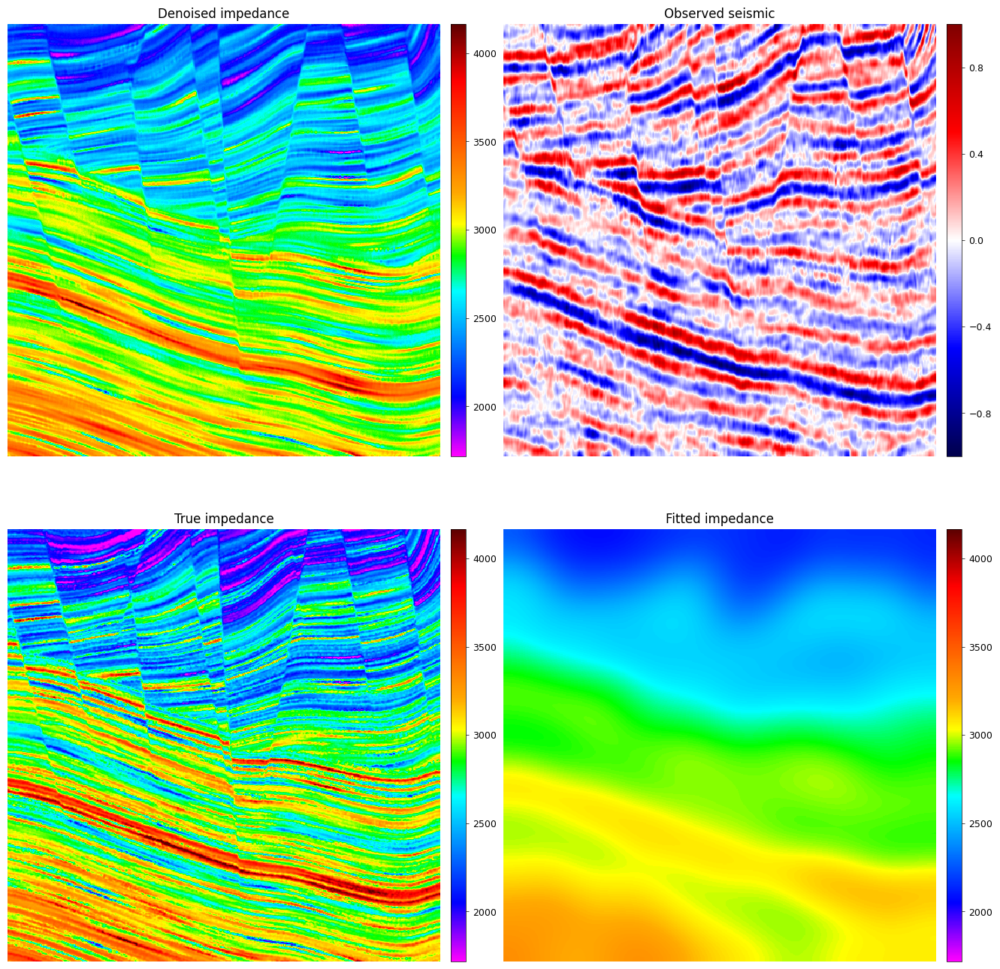

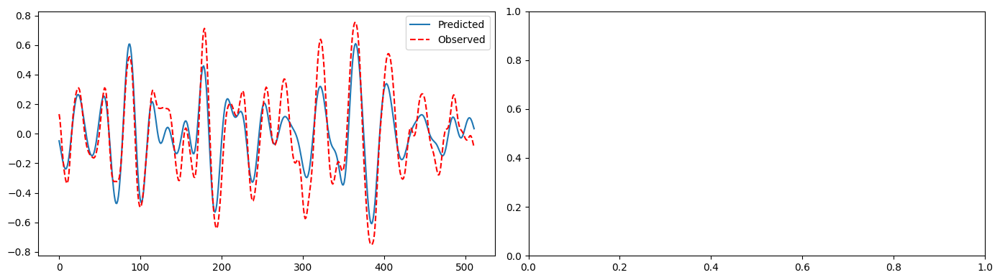

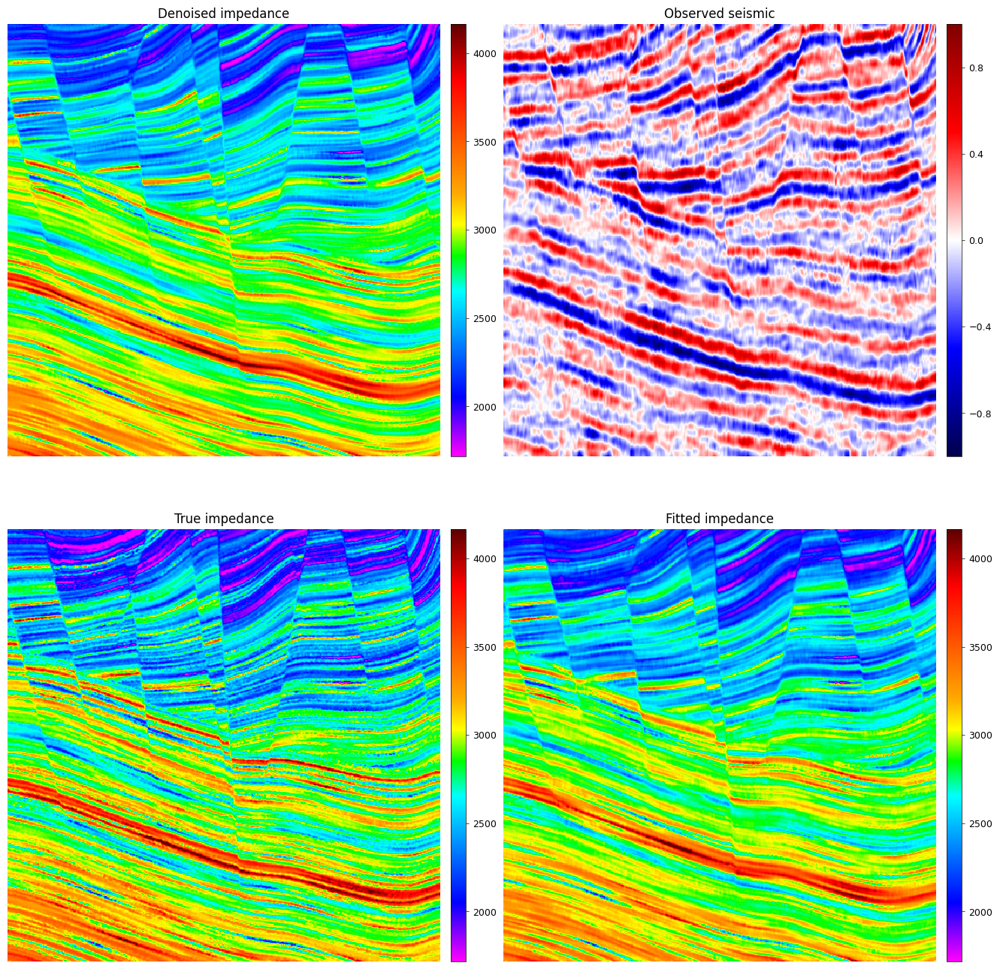

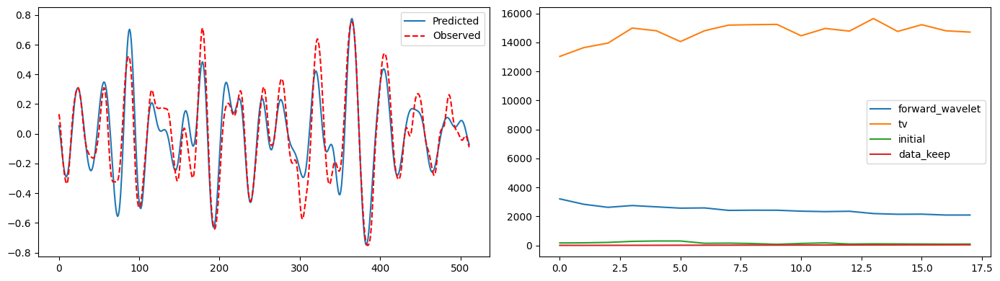

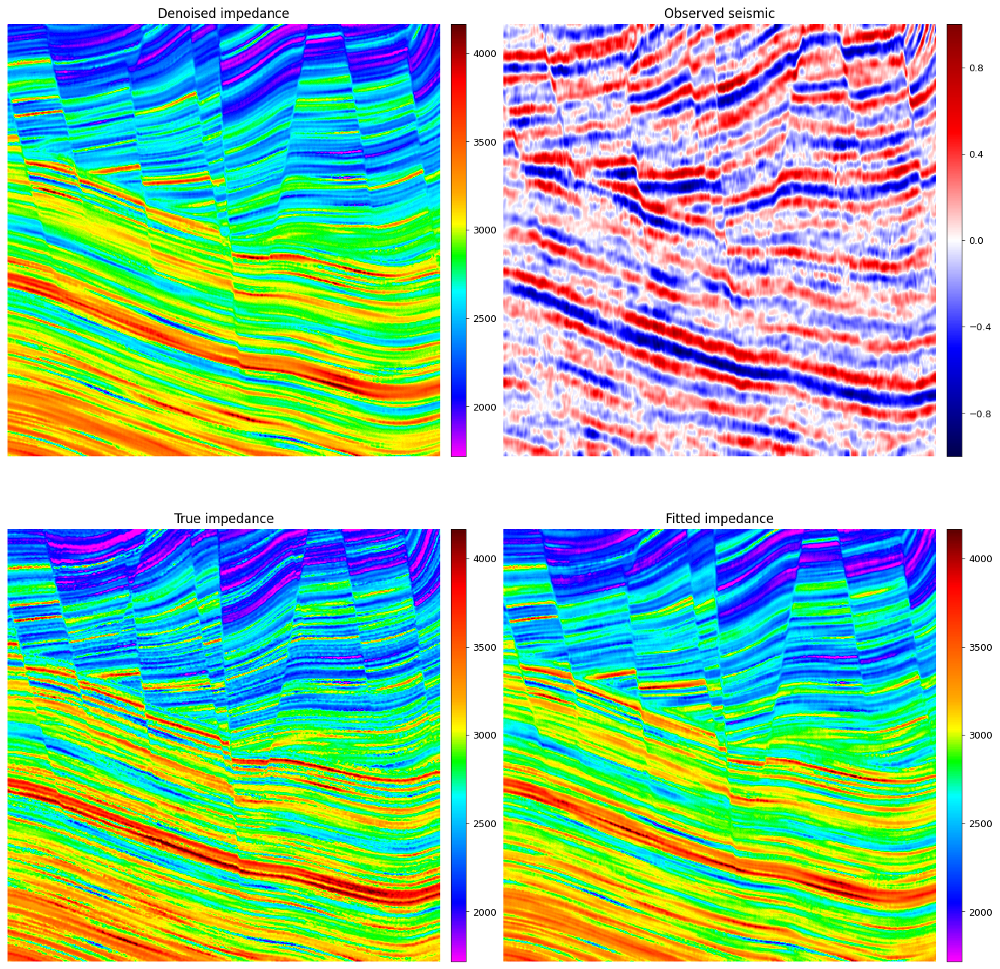

...

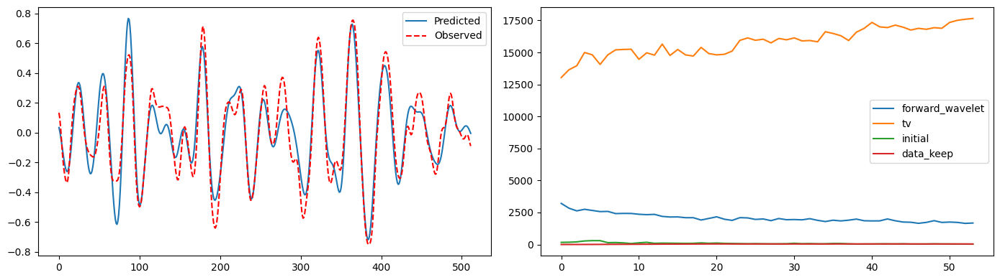

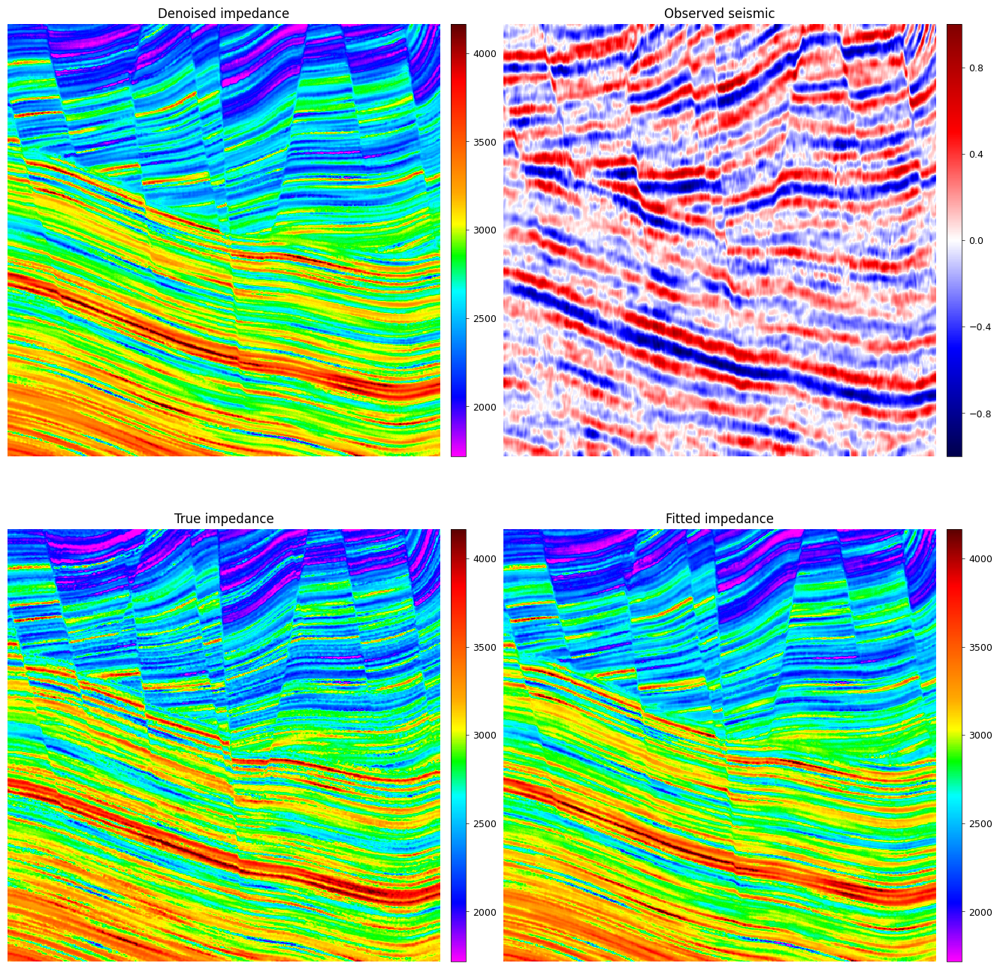

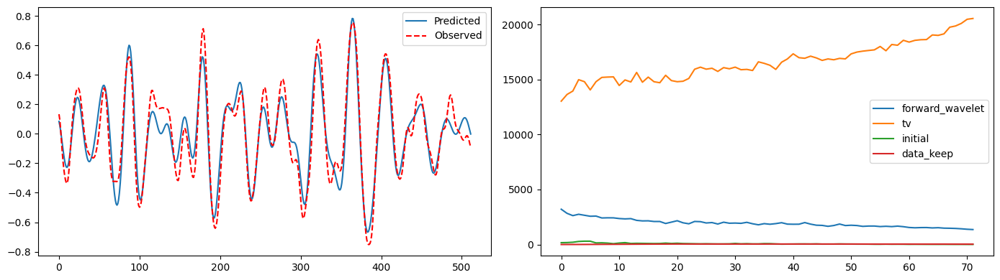

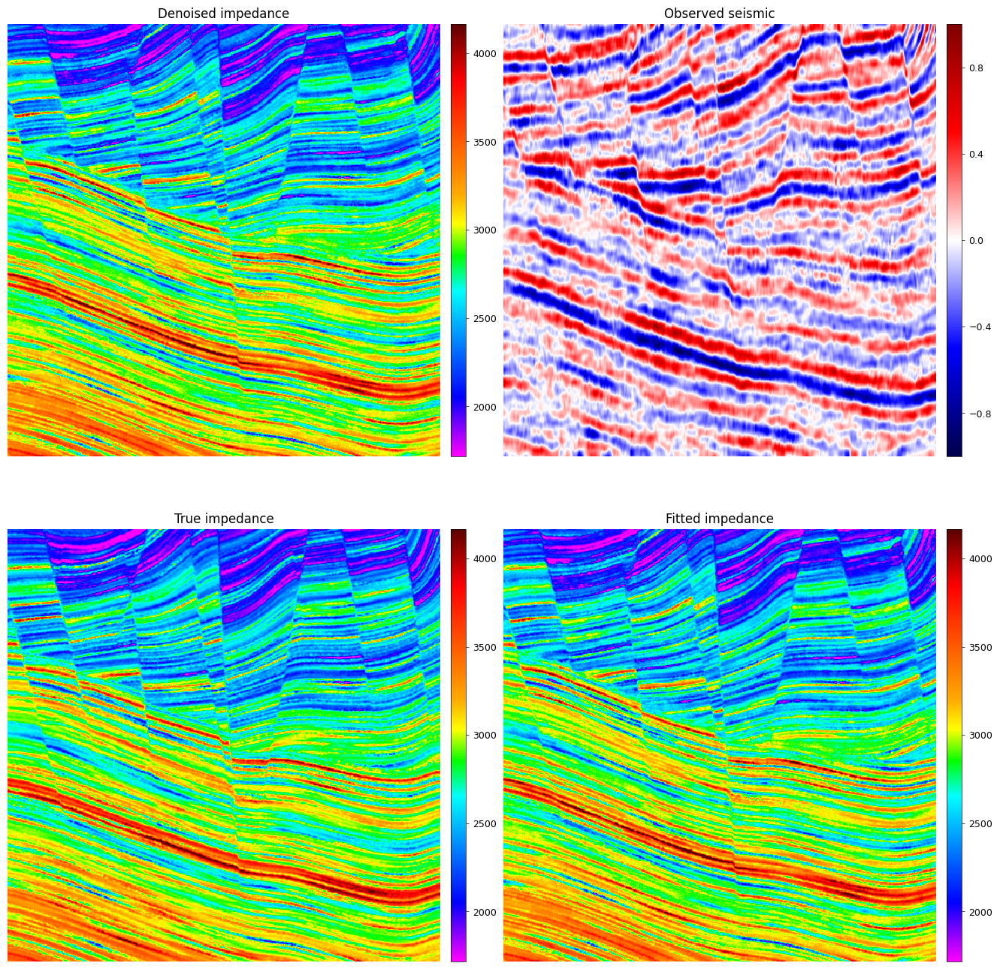

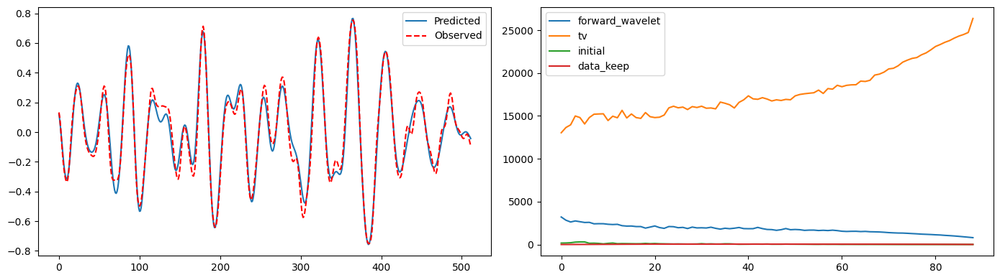

Metrics: {'RMSE': 230.31626892089844, 'PSNR': 23.38819385672638, 'SSIM': 0.48170214891433716, 'MAE': 169.18292236328125, 'CorrCoef': 0.8546078402421241, 'WellRMSE': 60.807655334472656, 'FixedAwayFromWellsRMSE': 230.69076538085938, 'ObservedSeismicRMSE_normalized': 0.05546381697058678, 'CleanSeismicRMSE': 0.004284603521227837} | UNet calls: 446 | Fitting updates: 890
Condition: 25 Hz, 5 dB


25 Hz, 5 dB:   0%|          | 0/90 [00:00<?, ?it/s]

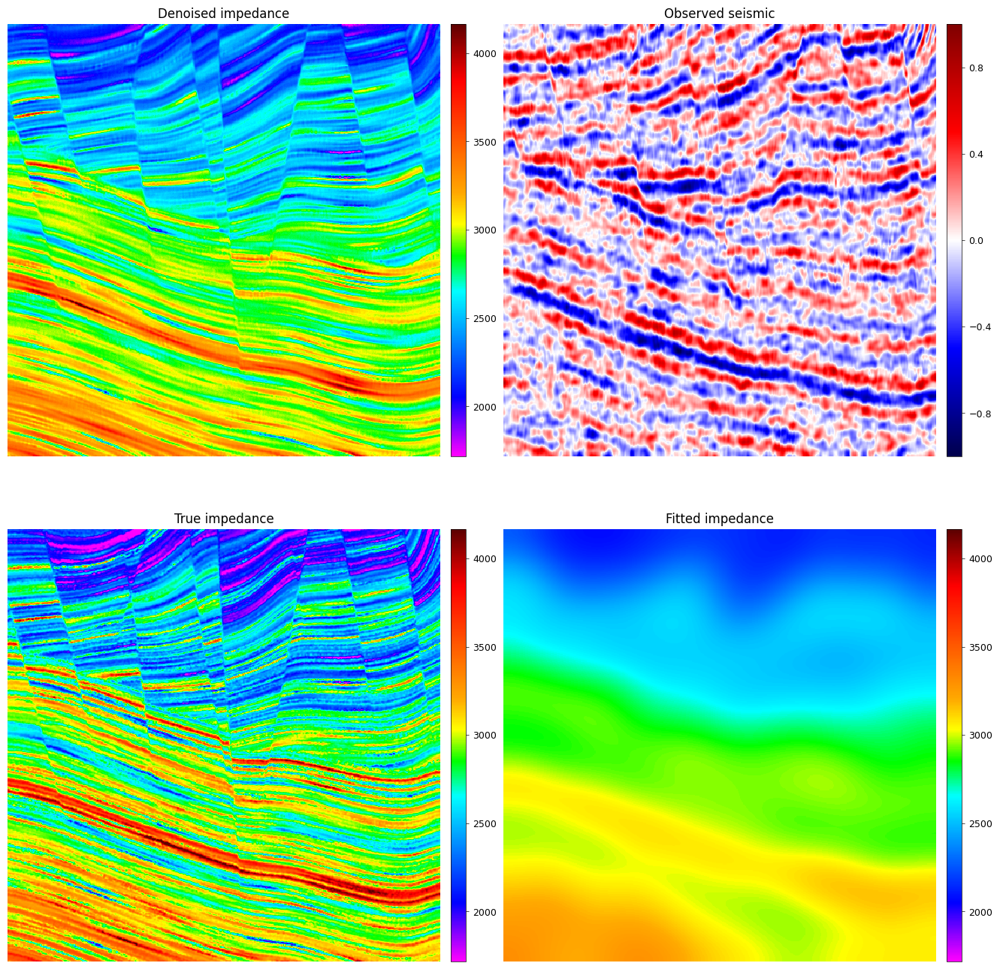

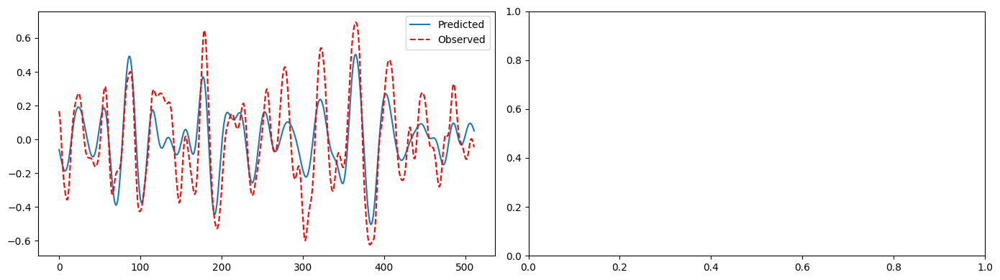

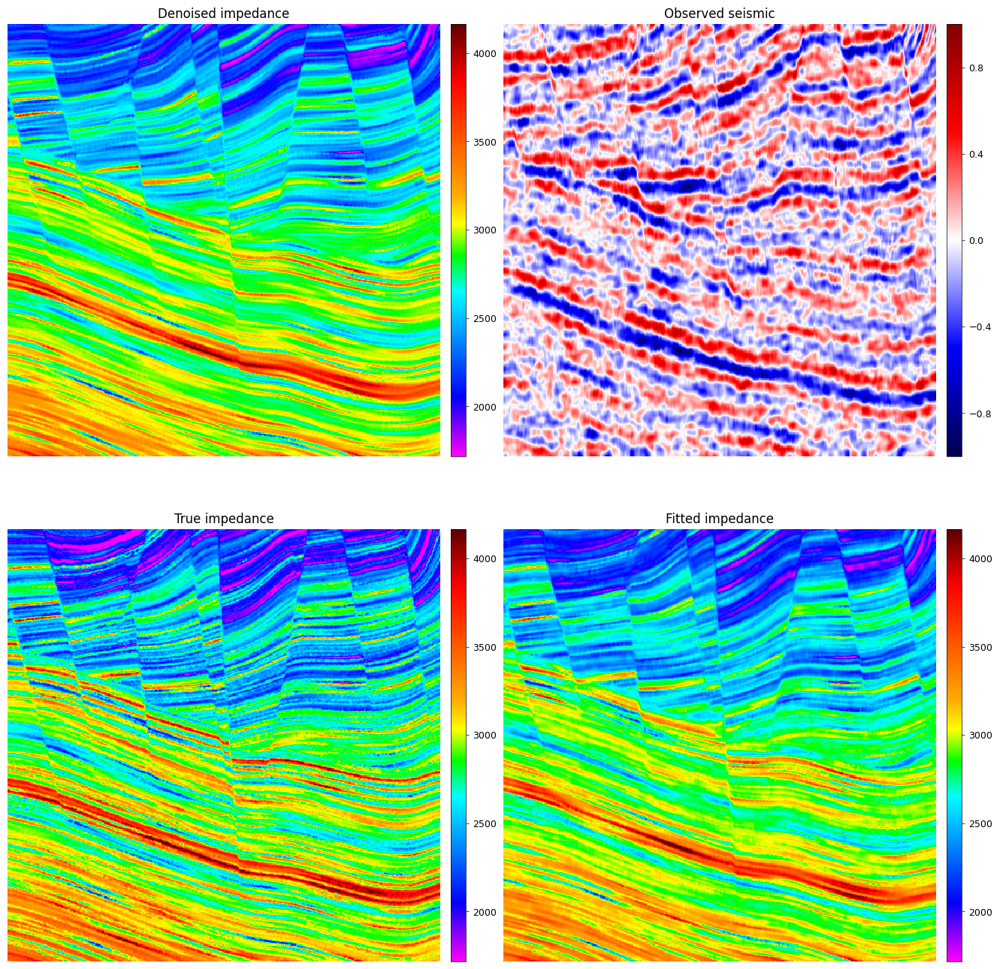

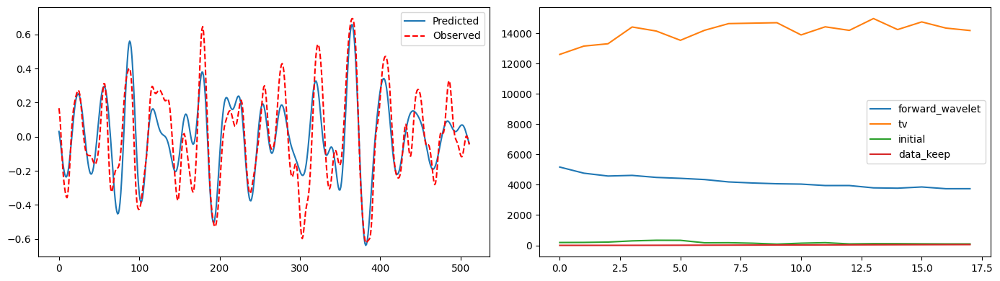

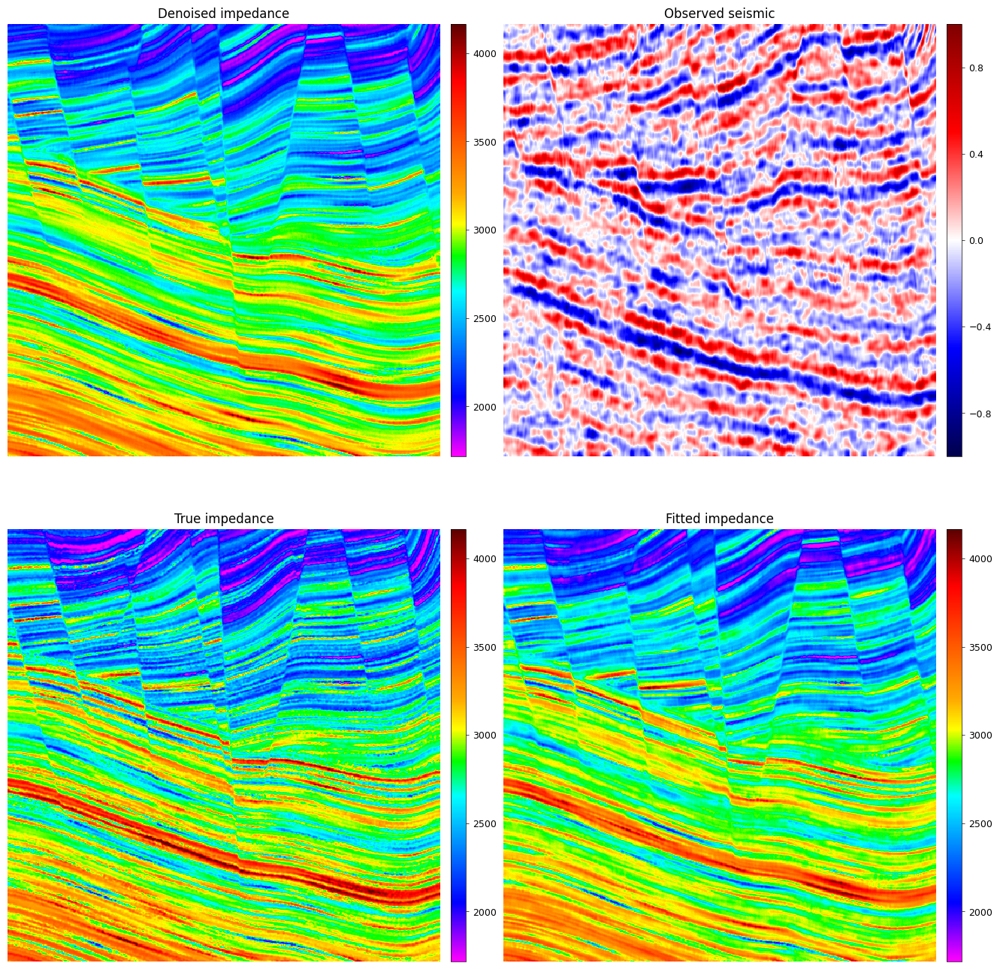

...

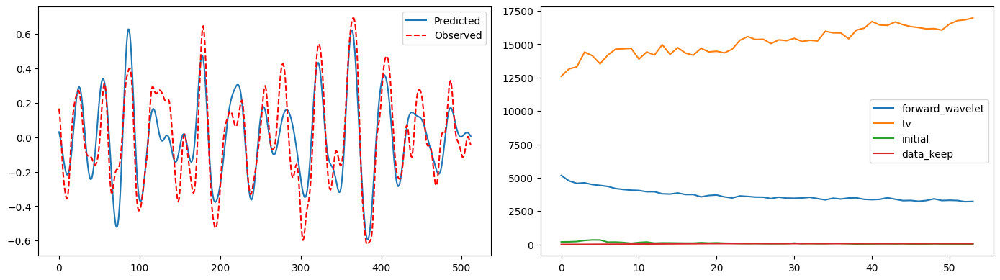

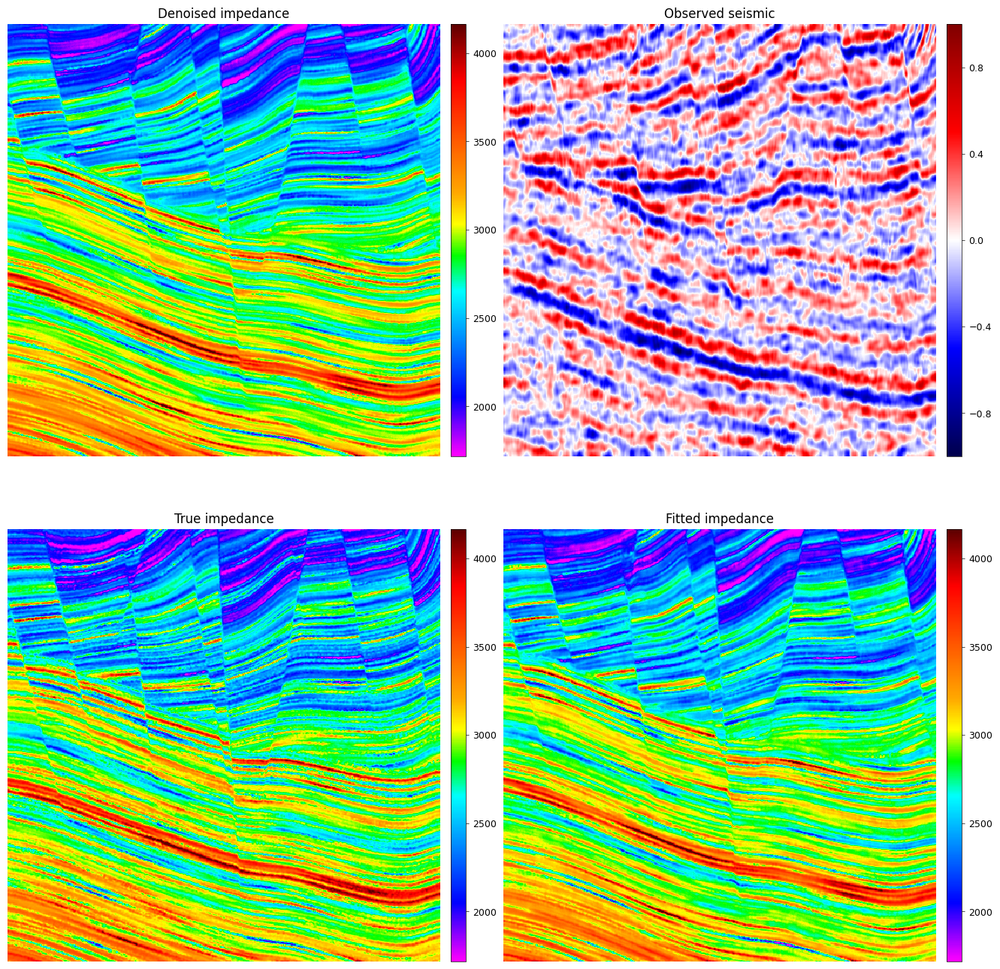

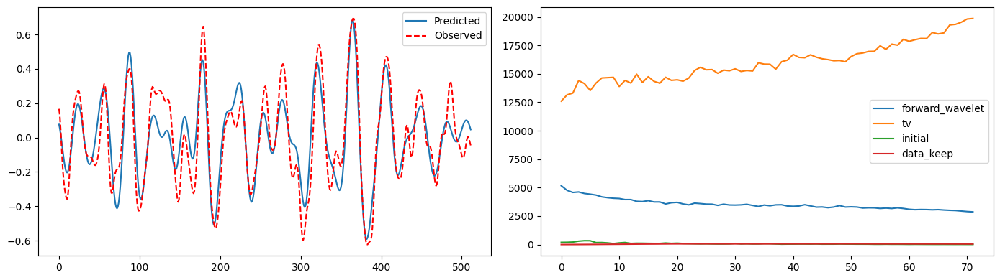

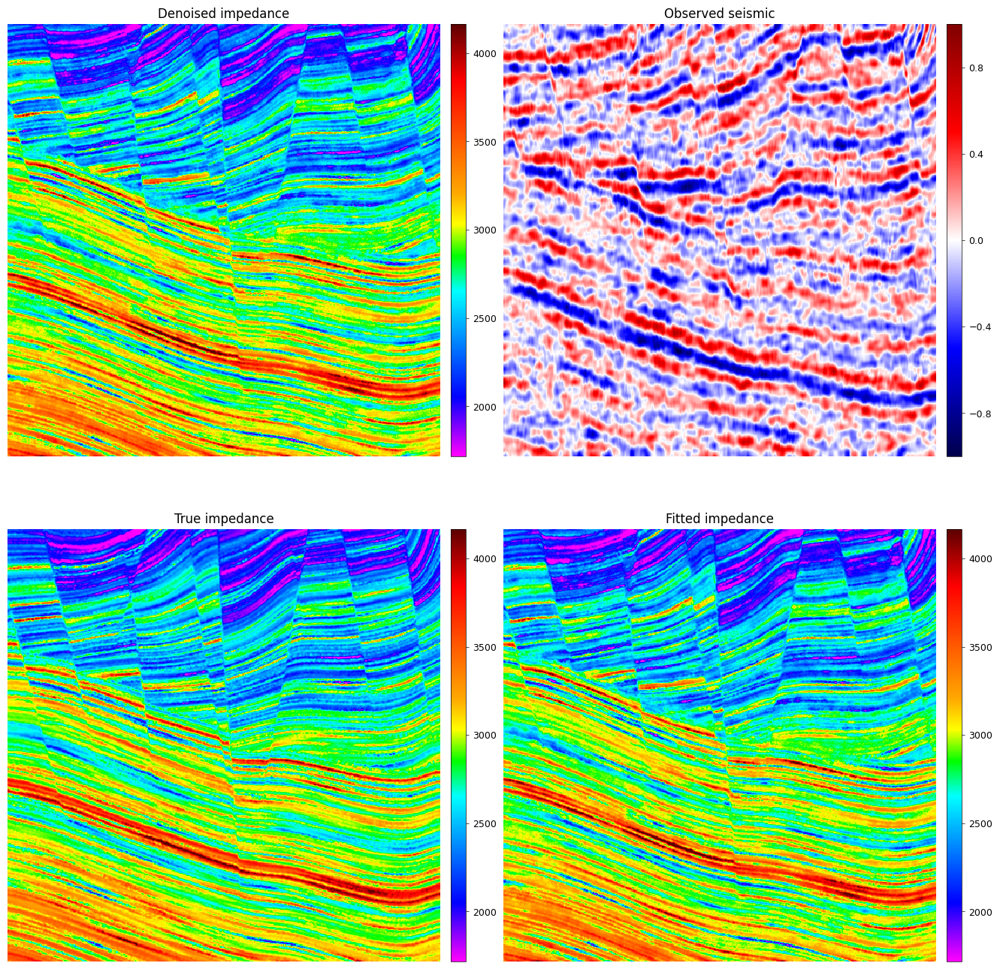

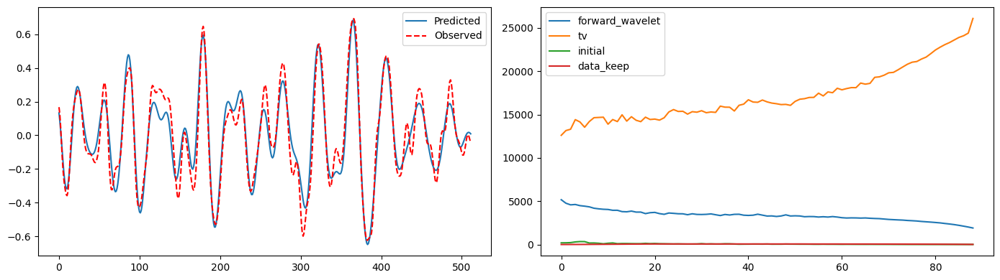

Metrics: {'RMSE': 237.59597778320312, 'PSNR': 23.117904499865197, 'SSIM': 0.47908875346183777, 'MAE': 175.5982208251953, 'CorrCoef': 0.8460114579066268, 'WellRMSE': 71.33365631103516, 'FixedAwayFromWellsRMSE': 238.0247039794922, 'ObservedSeismicRMSE_normalized': 0.08534012734889984, 'CleanSeismicRMSE': 0.006997744552791119} | UNet calls: 446 | Fitting updates: 890


In [15]:
results = []
run_records = []
def count_unet_forward(module, args, output):
    if torch.is_grad_enabled():
        raise AssertionError("The diffusion network must be called under no_grad.")
    calls["unet"] += 1

hook = unet.register_forward_hook(count_unet_forward)
try:
    for setting in settings:
        with np.load(data_dir / setting["file"], allow_pickle=False) as stored:
            arrays = {name: stored[name] for name in stored.files}
        for name in ["target", "initial_model", "well_image", "well_mask"]:
            if not np.array_equal(arrays[name], preview[name]):
                raise ValueError("Sensitivity settings must share the same true profile, initial model, and well conditions.")
        if (float(setting["scalars"]["imp_min"]) != imp_min or
                float(setting["scalars"]["imp_max"]) != imp_max):
            raise ValueError("All observation settings must use the same normalization bounds.")
        seis_slice = torch.from_numpy(arrays["observed"]).float().to(device)
        wavelet_mat = torch.from_numpy(arrays["wavelet"]).float().to(device)
        seis_min, seis_max = seis_slice.min(), seis_slice.max()
        seis_amplitude = torch.maximum(seis_min.abs(), seis_max.abs())
        seis = (seis_slice / seis_amplitude * 0.5 + 0.5).cpu().squeeze(0)
        cond_image = (seis.unsqueeze(0).to(device) - 0.5) / 0.5
        scaled_seismic = cond_image * torch.maximum(seis_min.abs(), seis_max.abs())
        scaled_seismic = torch.sign(scaled_seismic) * torch.pow(scaled_seismic.abs(), 1)
        cond_image_denoise = scaled_seismic / torch.maximum(
            scaled_seismic.min().abs(), scaled_seismic.max().abs())

        torch.manual_seed(seed)
        if device.type == "cuda":
            torch.cuda.manual_seed(seed)
        np.random.seed(seed)
        generator = torch.Generator(device=device).manual_seed(seed)
        # Preserve all three original noise draws; even unused draws affect the subsequent DDIM random sequence.
        unused_initial_noise = randn_tensor(
            image_shape, generator=generator, device=device, dtype=unet.dtype)
        scheduler.set_timesteps(10)
        old_grid = (np.arange(noise_schedule_steps) *
                    (scheduler.config.num_train_timesteps // noise_schedule_steps))[::-1].copy().astype(np.int64)
        scheduler2.set_timesteps(timesteps=old_grid)
        actual_noise = randn_tensor(
            image_shape, generator=generator, device=device, dtype=unet.dtype)
        image_fit_noise = scheduler2.add_noise(
            smoothed_norm.clone(), actual_noise, torch.tensor(int(timesteps[0])))
        unused_well_noise = randn_tensor(
            image_shape, generator=generator, device=device, dtype=unet.dtype)
        image_fit = smoothed_norm.clone()
        image_denoise = smoothed_norm.clone()
        image4upgrade = torch.zeros_like(smoothed_norm).requires_grad_(True)
        net = nn.Identity().to(device)
        opti = torch.optim.Adam([image4upgrade], lr=lr_scheduler[0])
        initial_func = partial(initial_fn, initial_image=smoothed_norm,
                               background_filter=background_filter)
        forward_wavelet_func = partial(
            forward_wavelet_fn, cond_image=cond_image.detach(), window=window_new,
            imp_min=imp_min, imp_max=imp_max, seis_min=seis_min, seis_max=seis_max)
        calls = {"unet": 0}
        physical_updates = 0
        fitting_calls = 0
        norm_dics = defaultdict(list)
        started = time.perf_counter()
        label = f'{setting["frequency_hz"]} Hz, {setting["snr_db"]} dB'
        print("Condition:", label)
        for i, timestep_value in tqdm(enumerate(timesteps), total=epochs, desc=label):
            timestep = int(timestep_value)
            if i:
                image_fit, norm_dic = data_fitting(
                    image4upgrade, image_denoise, net=net, opti_old=opti,
                    num_iterations=num_iterations, lr=lr_scheduler[i],
                    forward_fns={"forward_wavelet": forward_wavelet_func, "initial": initial_func},
                    scale={"forward_wavelet": forward_wavelet_weight, "tv": tv_weight,
                           "initial": initial_weight, "data_keep": datakeep_weight},
                    wavelet_mat=wavelet_mat)
                image_fit = image_fit.clone().detach()
                physical_updates += len(norm_dic["forward_wavelet"])
                fitting_calls += 1
                for key, value in norm_dic.items():
                    norm_dics[key].extend(value[-1:])
                image_fit_noise = scheduler2.add_noise(
                    image_fit, randn_tensor(image_shape, generator=generator,
                                            device=device, dtype=unet.dtype),
                    torch.tensor(max(timestep, noise_floor)))
            image_denoise, image_pred_ori, reverse_timesteps = denoise(
                timestep, image_fit_noise, N_rev, scheduler,
                cond_image=cond_image_denoise, well_image=well_image2, eta=eta,
                scale=[1.0, min(1.0, scale_scheduler_well[i])], generator=generator)
            image_denoise = image_denoise.clamp(-1, 1)

            if plot_interval and (i % plot_interval == 0 or i == epochs - 1):
                with torch.no_grad():
                    model_output_denorm = (image_denoise * 0.5 + 0.5) * (imp_max - imp_min) + imp_min
                    seis_forward = wavelet_forward(
                        wavelet_mat, image_denoise, window_new, seis_min, seis_max, imp_min, imp_max)
                plt.figure(figsize=section_figure_size(raw_image.shape[-2:], rows=2, cols=2, dataset=plot_options["dataset"]))
                for panel, array, title, colors, lo, hi in [
                    (1, model_output_denorm[0, 0], "Denoised impedance", cmap, plot_min, plot_max),
                    (2, cond_image[0, 0], "Observed seismic", cmap2, -1, 1),
                    (3, raw_image_denorm[0], "True impedance", cmap, plot_min, plot_max),
                    (4, (image_fit[0, 0] * 0.5 + 0.5) * (imp_max - imp_min) + imp_min,
                     "Fitted impedance", cmap, plot_min, plot_max)]:
                    plt.subplot(2, 2, panel)
                    plt.imshow(array.cpu().T, cmap=colors, vmin=lo, vmax=hi, aspect=aspect)
                    paper_section(plt.gca(), plt.gci(), impedance=colors is cmap,
                                  show_wells=False, **plot_options)
                    plt.title(title)
                    add_colorbar(plt.gcf(), plt.gci(), plt.gca())
                plt.tight_layout()
                plt.show()

                plt.figure(figsize=(14, 4))
                plt.subplot(121)
                trace = min(200, seis.shape[-2] - 1)
                plt.plot(seis_forward[0, 0, trace].cpu(), label="Predicted")
                plt.plot(cond_image[0, 0, trace].cpu(), "r--", label="Observed")
                plt.legend()
                plt.subplot(122)
                for key, value in norm_dics.items():
                    plt.plot(value, label=key)
                if norm_dics:
                    plt.legend()
                plt.tight_layout()
                plt.show()

        expected_calls = sum(min(N_rev, int(t)) if int(t) else 1 for t in timesteps)
        assert calls["unet"] == expected_calls
        assert fitting_calls == max(epochs - 1, 0)
        assert physical_updates == num_iterations * max(epochs - 1, 0)
        physical = ((image_denoise / 2 + 0.5).clamp(0, 1) *
                    (imp_max - imp_min) + imp_min).cpu()
        if not torch.isfinite(physical).all():
            raise FloatingPointError("The inverted model contains nonfinite values.")
        metrics = calc_metrics(physical[0, 0], raw_image_denorm[0].cpu(), imp_max - imp_min)
        with torch.no_grad():
            synthetic = wavelet_forward(
                wavelet_mat, image_denoise, window_new, seis_min, seis_max, imp_min, imp_max).cpu()
        error = physical[0, 0] - raw_image_denorm[0].cpu()
        well_mask = torch.from_numpy(arrays["well_mask"][0, 0]).bool()
        fixed_mask = torch.from_numpy(arrays["maximum_well_mask"][0, 0]).bool()
        metrics["WellRMSE"] = float(error[well_mask].square().mean().sqrt())
        metrics["FixedAwayFromWellsRMSE"] = float(error[~fixed_mask].square().mean().sqrt())
        metrics["ObservedSeismicRMSE_normalized"] = float((synthetic - cond_image.cpu()).square().mean().sqrt())
        clean_seismic = torch.from_numpy(arrays["clean"]).float()
        metrics["CleanSeismicRMSE"] = float(
            (synthetic * float(seis_amplitude) - clean_seismic).square().mean().sqrt())
        stem = Path(setting["file"]).stem
        np.save(output_dir / f"{stem}_seed_{seed}.npy", physical[0, 0].numpy())
        np.save(output_dir / f"{stem}_wavelet.npy", wavelet_mat.cpu().numpy())
        record = dict(file=setting["file"], frequency_hz=setting["frequency_hz"],
                      snr_db=setting["snr_db"], well_count=int(setting["scalars"]["well_count"]), seed=seed, metrics=metrics,
                      physical_updates=physical_updates, unet_calls=calls["unet"],
                      norm_dics=dict(norm_dics), elapsed_seconds=time.perf_counter() - started)
        (output_dir / f"{stem}_seed_{seed}.json").write_text(
            json.dumps(record, indent=2) + "\n", encoding="utf-8")
        results.append(dict(label=label, model=physical[0, 0],
                            observed=cond_image[0, 0].cpu()))
        run_records.append(record)
        print("Metrics:", metrics, "| UNet calls:", calls["unet"],
              "| Fitting updates:", physical_updates)
        del image4upgrade, net, opti
finally:
    hook.remove()


## 12. Evaluation, Plotting, and Saving for Each Observation Setting


,frequency_hz,snr_db,seed,physical_updates,unet_calls,RMSE,PSNR,SSIM,MAE,CorrCoef,WellRMSE,FixedAwayFromWellsRMSE,ObservedSeismicRMSE_normalized,CleanSeismicRMSE
0,25,30,42,890,446,179.159592,25.569885,0.564616,132.681488,0.907427,52.221710,179.438599,0.018733,0.001396
1,25,20,42,890,446,196.861404,24.751475,0.524882,145.696625,0.889245,52.151928,197.199234,0.024513,0.001848
2,25,10,42,890,446,230.316269,23.388194,0.481702,169.182922,0.854608,60.807655,230.690765,0.055464,0.004285
3,25,5,42,890,446,237.595978,23.117904,0.479089,175.598221,0.846011,71.333656,238.024704,0.085340,0.006998


,frequency_hz,snr_db,seed,physical_updates,unet_calls,RMSE_current,PSNR,SSIM_current,MAE_current,CorrCoef_current,...,ObservedSeismicRMSE_normalized,CleanSeismicRMSE,RMSE_paper,MAE_paper,SSIM_paper,CorrCoef_paper,RMSE_difference,MAE_difference,SSIM_difference,CorrCoef_difference
0,25,30,42,890,446,179.159592,25.569885,0.564616,132.681488,0.907427,...,0.018733,0.001396,179.159073,132.681229,0.564616,0.907428,0.000519,0.000259,-5.960464e-07,-5.561797e-07
1,25,20,42,890,446,196.861404,24.751475,0.524882,145.696625,0.889245,...,0.024513,0.001848,196.862717,145.697388,0.524880,0.889243,-0.001312,-0.000763,1.609325e-06,1.283355e-06
2,25,10,42,890,446,230.316269,23.388194,0.481702,169.182922,0.854608,...,0.055464,0.004285,230.316223,169.183136,0.481697,0.854608,0.000046,-0.000214,4.798174e-06,7.295634e-08
3,25,5,42,890,446,237.595978,23.117904,0.479089,175.598221,0.846011,...,0.085340,0.006998,237.595444,175.598511,0.479084,0.846012,0.000534,-0.000290,5.125999e-06,-1.199918e-07


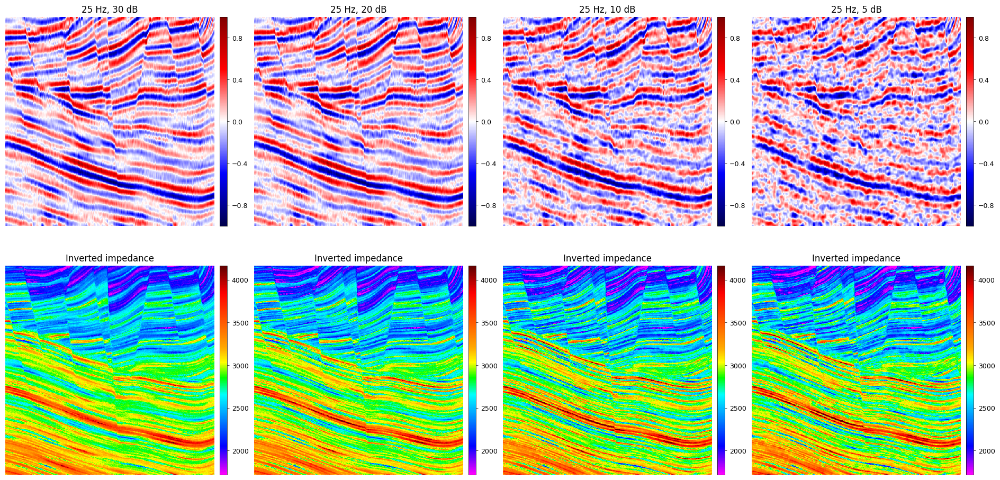

In [16]:
table = pd.DataFrame([
    dict(frequency_hz=r["frequency_hz"], snr_db=r["snr_db"], seed=r["seed"],
         physical_updates=r["physical_updates"], unet_calls=r["unet_calls"], **r["metrics"])
    for r in run_records])
display(table)
table.to_csv(output_dir / "metrics.csv", index=False)

fig, axes = plt.subplots(2, len(results), figsize=section_figure_size(raw_image.shape[-2:], rows=2, cols=len(results), panel_width=4, dataset=plot_options["dataset"]), squeeze=False)
for j, result in enumerate(results):
    ax = axes[0, j]
    shown = ax.imshow(result["observed"].T, cmap=cmap2, vmin=-1, vmax=1, aspect=aspect)
    paper_section(ax, ax.images[-1], impedance=False,
                  show_wells=False, **plot_options)
    ax.set_title(result["label"])
    add_colorbar(fig, shown, ax)
    ax = axes[1, j]
    shown = ax.imshow(result["model"].T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
    paper_section(ax, ax.images[-1], impedance=True,
                  show_wells=False, **plot_options)
    ax.set_title("Inverted impedance")
    add_colorbar(fig, shown, ax)
plt.tight_layout()
plt.savefig(output_dir / "sensitivity_results.png", dpi=160, bbox_inches="tight")
plt.show()
